# Geometric Morphometric Machine Learning Classification Pipeline
## SAM vs MAM vs ONC Multi-Class Classification & Out-of-Sample Validation Pipeline

### 📌 Executive Summary & Experimental Objectives
This notebook implements an end-to-end **Geometric Morphometric (GM) Machine Learning Pipeline** for 3-way multi-class nutritional status classification (**SAM** vs **MAM** vs **ONC**) following rigorous morphometric feature selection:
1. **Initial Raw Landmark Coordinates (40 Variables)**: Digitized left arm shape configurations consisting of 20 points (4 anatomical landmarks + 16 contour semilandmarks) yielding an initial 40 Cartesian coordinates ($X, Y$).
2. **Alignment Transformation (Procrustes Coordinates)**: Raw coordinates undergo Full Generalized Procrustes Analysis (fGPA) for the training dataset or Full Ordinary Procrustes Analysis (fOPA) for out-of-sample validation to eliminate scale, translation, and orientation shifts.
3. **Allometric Size Correction (Shape Residuals $X^{P \text{res}}$)**: Multivariate linear regression of aligned Procrustes coordinates against log Centroid Size ($\log CS$). The resulting residuals ($X^{P \text{res}}$) isolate pure, size-independent shape features.
4. **Collinearity Mitigation & Landmark Selection (36 Variables)**: Two redundant landmarks (Landmarks 2 and 3) are eliminated to prevent linear dependence and numerical matrix inversion instability in classifiers (LDA, Logistic Regression), reducing the feature space to 18 landmarks / 36 direct allometric residual shape coordinates.
5. **Direct Coordinates Selected Over PCA**: The classifiers strictly receive the direct 36 $X, Y$ allometric residual shape coordinates of the 18 landmarks to preserve direct anatomical interpretability without PCA component reduction.
6. **Datasets & Out-of-Sample Protocol**:
   - **Training Dataset**: Geometric Transformation Augmented Dataset (`final_balanced_dataset_geometric_augmented.csv`) with 707 SAM, 707 MAM, and 707 ONC specimens (2,121 total samples).
   - **Testing & Validation Dataset**: Pristine Real Dataset (`final_cleaned_dataset_full.csv`) with 217 SAM, 707 MAM, and 707 ONC real-world specimens (1,631 total samples) used strictly for out-of-sample testing.
7. **Machine Learning Classifiers**: Benchmark evaluation across 8 ML classifiers (Logistic Regression, LDA, SVM, Random Forest, Extra Trees, Gradient Boosting, k-NN, and XGBoost) with 10-Fold Stratified Cross-Validation and out-of-sample holdout testing.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, f1_score, recall_score, precision_score, balanced_accuracy_score, confusion_matrix, accuracy_score, roc_curve, roc_auc_score
from sklearn.linear_model import LogisticRegression, LinearRegression, LinearRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.feature_selection import f_classif
from sklearn.decomposition import PCA
from xgboost import XGBClassifier
import warnings
warnings.filterwarnings('ignore')

# Set global reproducibility seeds and plotting aesthetic
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.family'] = 'sans-serif'
print("✅ Libraries and aesthetic dependencies loaded successfully.")

✅ Libraries and aesthetic dependencies loaded successfully.


## Section 1: Dataset Ingestion & Preprocessing
We load the **Geometric Augmented Training Dataset** (`final_balanced_dataset_geometric_augmented.csv`) and the **Pristine Real Testing & Validation Dataset** (`final_cleaned_dataset_full.csv`). We extract demographic variables, encode gender (`Male`=0, `Female`=1), and map raw 2D landmark coordinates ($X_i, Y_i$).

In [2]:
# Load Training Dataset (Geometric Transformation Augmented) and Pristine Test Dataset
#train_path = r"e:\ap-govt-EDA-model-tainning-testing\GM_out_of_sample_classification-main\GM_out_of_sample_classification-ap-govt\Experiment and Modeling\version2\final_balanced_dataset_geometric_augmented.csv"
train_path = r"E:\ap-govt-EDA-model-tainning-testing\GM_out_of_sample_classification-main\GM_out_of_sample_classification-ap-govt\Experiment and Modeling\version3\train_dataset_augmented.csv"
test_path = r"E:\ap-govt-EDA-model-tainning-testing\GM_out_of_sample_classification-main\GM_out_of_sample_classification-ap-govt\Experiment and Modeling\version3\test_dataset_original.csv"

if not os.path.exists(train_path):
    train_path = "final_balanced_dataset_geometric_augmented.csv"
if not os.path.exists(test_path):
    test_path = "final_cleaned_dataset_full.csv"

df_train_raw = pd.read_csv(train_path)
df_test_raw = pd.read_csv(test_path)

# Encode Gender for both datasets
df_train_raw['gender_num'] = df_train_raw['gender'].map({'M': 0, 'F': 1, 'Male': 0, 'Female': 1}).fillna(0)
df_test_raw['gender_num'] = df_test_raw['gender'].map({'M': 0, 'F': 1, 'Male': 0, 'Female': 1}).fillna(0)

# Identify raw 2D landmark coordinate columns and exclude redundant Landmarks 2 and 3
all_landmark_ids = [i for i in range(1, 23) if f'X{i}' in df_train_raw.columns and f'Y{i}' in df_train_raw.columns]
landmark_ids = [i for i in all_landmark_ids if i not in [2, 3]]
K = len(landmark_ids)

print("="*70)
print("DATASET INGESTION SUMMARY")
print("="*70)
print(f"Training Dataset Shape (Geometric Augmented): {df_train_raw.shape}")
print(df_train_raw['Class_Type'].value_counts().to_string())

print(f"Testing & Validation Dataset Shape (Pristine Real): {df_test_raw.shape}")
print(df_test_raw['Class_Type'].value_counts().to_string())
print(f"All Landmark Points Present: {all_landmark_ids}")
print(f"Selected Landmark Points (Excluding Redundant LM2 & LM3): {landmark_ids} (K = {K} landmarks)")


DATASET INGESTION SUMMARY
Training Dataset Shape (Geometric Augmented): (5637, 105)
Class_Type
onc    4223
mam     707
sam     707
Testing & Validation Dataset Shape (Pristine Real): (1240, 105)
Class_Type
onc    1056
mam     141
sam      43
All Landmark Points Present: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 12, 13, 14, 15, 16, 17, 18, 19, 20]
Selected Landmark Points (Excluding Redundant LM2 & LM3): [1, 4, 5, 6, 7, 8, 9, 10, 12, 13, 14, 15, 16, 17, 18, 19, 20] (K = 17 landmarks)


## Section 2: Geometric Morphometric Superimposition (GPA Pipeline)
We execute the 5-step shape alignment pipeline:
1. **Raw Coordinates**: Initial digitized anatomical landmark locations ($X_i, Y_i$).
2. **Centering (Translation Removal)**: Translating shapes to origin $(0,0)$ by subtracting centroid coordinates $(ar{X}, ar{Y})$.
3. **Scaling (Size Removal)**: Normalizing by Centroid Size ($CS = \sqrt{\sum ((X_i - ar{X})^2 + (Y_i - ar{Y})^2)}$).
4. **Generalized Procrustes Analysis (GPA - Rigid Rotation Removal)**: Iteratively aligning shapes to consensus mean via Singular Value Decomposition (SVD) Singular Rotations.
5. **Horizontal Orientation Alignment**: Aligning central axis horizontally for wireframe visualization.

In [3]:
# Geometric Morphometric GPA Core Helper Functions
def center_shape(shape):
    centroid = np.mean(shape, axis=0)
    return shape - centroid, centroid

def get_centroid_size(shape):
    centroid = np.mean(shape, axis=0)
    return np.sqrt(np.sum((shape - centroid) ** 2))

def scale_shape(shape):
    cs = get_centroid_size(shape)
    if cs == 0:
        return shape, 1.0
    return shape / cs, cs

def proc_rotate(shape, reference):
    H = shape.T @ reference
    U, S, Vt = np.linalg.svd(H)
    R = Vt.T @ U.T
    if np.linalg.det(R) < 0:
        Vt[1, :] *= -1
        R = Vt.T @ U.T
    return shape @ R

def proc_gpa(shapes, max_iter=20, tol=1e-7, consensus_type='mean'):
    K, D, N = shapes.shape
    aligned = np.zeros_like(shapes)
    for i in range(N):
        sh, _ = center_shape(shapes[:, :, i])
        sh, _ = scale_shape(sh)
        aligned[:, :, i] = sh

    mshape = np.mean(aligned, axis=2)
    mshape, _ = scale_shape(mshape)

    for it in range(max_iter):
        new_aligned = np.zeros_like(aligned)
        for i in range(N):
            new_aligned[:, :, i] = proc_rotate(aligned[:, :, i], mshape)
        new_mshape = np.mean(new_aligned, axis=2)
        new_mshape, _ = scale_shape(new_mshape)
        diff = np.sqrt(np.sum((new_mshape - mshape) ** 2))
        aligned = new_aligned
        mshape = new_mshape
        if diff < tol:
            break
    return {'rotated': aligned, 'mshape': mshape, 'iterations': it + 1}

def rotate_shapes(shapes, mean_shape):
    K, D, N = shapes.shape
    p1 = mean_shape[1, :] if K > 1 else mean_shape[0, :]
    p0 = mean_shape[0, :]
    vec = p1 - p0
    angle = -np.arctan2(vec[1], vec[0])
    cos_a, sin_a = np.cos(angle), np.sin(angle)
    R = np.array([[cos_a, -sin_a], [sin_a, cos_a]])
    
    mean_rot = mean_shape @ R
    shapes_rot = np.zeros_like(shapes)
    for i in range(N):
        shapes_rot[:, :, i] = shapes[:, :, i] @ R
    return shapes_rot, mean_rot

print("✅ Generalized Procrustes Analysis (GPA) engine initialized.")

def compute_allometric_residuals_df(df_train, df_test, gpa_cols):
    """Compute allometric shape residuals by regressing Procrustes coordinates against log(Centroid_Size)"""
    train_log_cs = np.log(df_train['Centroid_Size'].values)
    test_log_cs = np.log(df_test['Centroid_Size'].values)
    
    train_residuals = np.zeros((len(df_train), len(gpa_cols)))
    test_residuals = np.zeros((len(df_test), len(gpa_cols)))
    res_cols = [c.replace('GPA_', 'Res_') for c in gpa_cols]
    
    for idx, col in enumerate(gpa_cols):
        y_tr = df_train[col].values
        y_te = df_test[col].values
        
        lr_model = LinearRegression()
        lr_model.fit(train_log_cs.reshape(-1, 1), y_tr)
        
        train_residuals[:, idx] = y_tr - lr_model.predict(train_log_cs.reshape(-1, 1))
        test_residuals[:, idx] = y_te - lr_model.predict(test_log_cs.reshape(-1, 1))
        
    df_tr_res = pd.DataFrame(train_residuals, columns=res_cols)
    df_te_res = pd.DataFrame(test_residuals, columns=res_cols)
    return df_tr_res, df_te_res, res_cols


✅ Generalized Procrustes Analysis (GPA) engine initialized.


In [4]:
# Anatomical Arm Wireframe Plotting Helper
id_to_idx = {lid: i for i, lid in enumerate(landmark_ids)}

upper_contour_ids = [1, 12, 14, 16, 18, 10, 8, 6, 20]
upper_contour_idx = [id_to_idx[lid] for lid in upper_contour_ids if lid in id_to_idx]
lower_contour_ids = [4, 13, 15, 17, 9, 7, 5, 19]
lower_contour_idx = [id_to_idx[lid] for lid in lower_contour_ids if lid in id_to_idx]
shoulder_edge_idx = [id_to_idx[1], id_to_idx[4]] if (1 in id_to_idx and 4 in id_to_idx) else []
wrist_edge_idx = [id_to_idx[lid] for lid in [20, 3, 19] if lid in id_to_idx]
dashed_cross_ids = [[12, 4], [14, 13], [16, 15], [18, 17], [10, 9], [8, 7], [6, 5]]
dashed_cross_idx = [[id_to_idx[lid] for lid in seg if lid in id_to_idx] for seg in dashed_cross_ids]
midline_idx = [id_to_idx[lid] for lid in [2, 3] if lid in id_to_idx]

def plot_arm_wireframe(ax, shapes, color='black', alpha_solid=0.8, alpha_dashed=0.4, 
                       lw_solid=1.5, lw_dashed=1.0, alpha_scatter=0.6, s=20, 
                       label=None, show_labels=True, monochrome=True):
    shapes_arr = np.asarray(shapes)
    if shapes_arr.ndim == 2:
        shapes_arr = shapes_arr[:, :, np.newaxis]
    elif shapes_arr.ndim == 3 and shapes_arr.shape[1] != 2:
        shapes_arr = np.transpose(shapes_arr, (1, 2, 0))

    N_samples = shapes_arr.shape[2]
    c_upper = color if monochrome else 'red'
    c_lower = color if monochrome else 'blue'
    c_shoulder = color if monochrome else 'purple'
    c_wrist = color if monochrome else 'green'
    c_cross = color if monochrome else 'gray'
    c_midline = color if monochrome else 'gold'

    if alpha_scatter > 0 and s > 0:
        all_x = shapes_arr[:, 0, :].flatten()
        all_y = shapes_arr[:, 1, :].flatten()
        ax.scatter(all_x, all_y, color=color, alpha=alpha_scatter, s=s, zorder=3, label=label if label else None)

    for i in range(N_samples):
        sh = shapes_arr[:, :, i]
        if upper_contour_idx:
            ax.plot(sh[upper_contour_idx, 0], sh[upper_contour_idx, 1], color=c_upper, 
                    alpha=alpha_solid, linewidth=lw_solid, linestyle='-', zorder=5)
        if lower_contour_idx:
            ax.plot(sh[lower_contour_idx, 0], sh[lower_contour_idx, 1], color=c_lower, 
                    alpha=alpha_solid, linewidth=lw_solid, linestyle='-', zorder=5)
        if shoulder_edge_idx:
            ax.plot(sh[shoulder_edge_idx, 0], sh[shoulder_edge_idx, 1], color=c_shoulder, 
                    alpha=alpha_solid, linewidth=lw_solid, linestyle='-', zorder=5)
        if wrist_edge_idx:
            ax.plot(sh[wrist_edge_idx, 0], sh[wrist_edge_idx, 1], color=c_wrist, 
                    alpha=alpha_solid, linewidth=lw_solid, linestyle='-', zorder=5)
        for seg in dashed_cross_idx:
            ax.plot(sh[seg, 0], sh[seg, 1], color=c_cross, 
                    alpha=alpha_dashed, linewidth=lw_dashed, linestyle='--', zorder=4)
        if len(midline_idx) >= 2:
            ax.plot(sh[midline_idx, 0], sh[midline_idx, 1], color=c_midline, 
                    alpha=alpha_solid * 0.8, linewidth=lw_dashed, linestyle=':', zorder=4)

print("✅ Wireframe plotting routines initialized.")

✅ Wireframe plotting routines initialized.


## Section 2.1: Step-by-Step Visual Demonstration of GPA Operations

Below, we visually demonstrate the **5 sequential mathematical operations** of Generalized Procrustes Analysis (GPA) on arm wireframes across all three classes (**SAM**, **MAM**, **ONC**):

1. **Step 1: Raw Digitized Landmark Coordinates** ($X_i, Y_i$) — Shows unaligned digitized positions, scales, and random $360^\circ$ synthetic SAM rotations.
2. **Step 2: Translation Removal (Centering to Origin $(0,0)$)** — Subtracts centroid $(\bar{X}, \bar{Y})$ so all centroids coincide at origin.
3. **Step 3: Scaling Removal (Centroid Size Normalization $CS=1.0$)** — Divides coordinates by Centroid Size $CS = \sqrt{\sum ((X_i - \bar{X})^2 + (Y_i - \bar{Y})^2)}$.
4. **Step 4: Procrustes Superimposition (SVD Rigid Rotation Removal)** — Rotates each shape via Singular Value Decomposition ($H = X^T \bar{X} = U S V^T \implies R = V U^T$) to align with consensus mean shape.
5. **Step 5: Horizontal Orientation Alignment** — Rotates consensus major axis horizontally along the X-axis for standardized anatomical display.

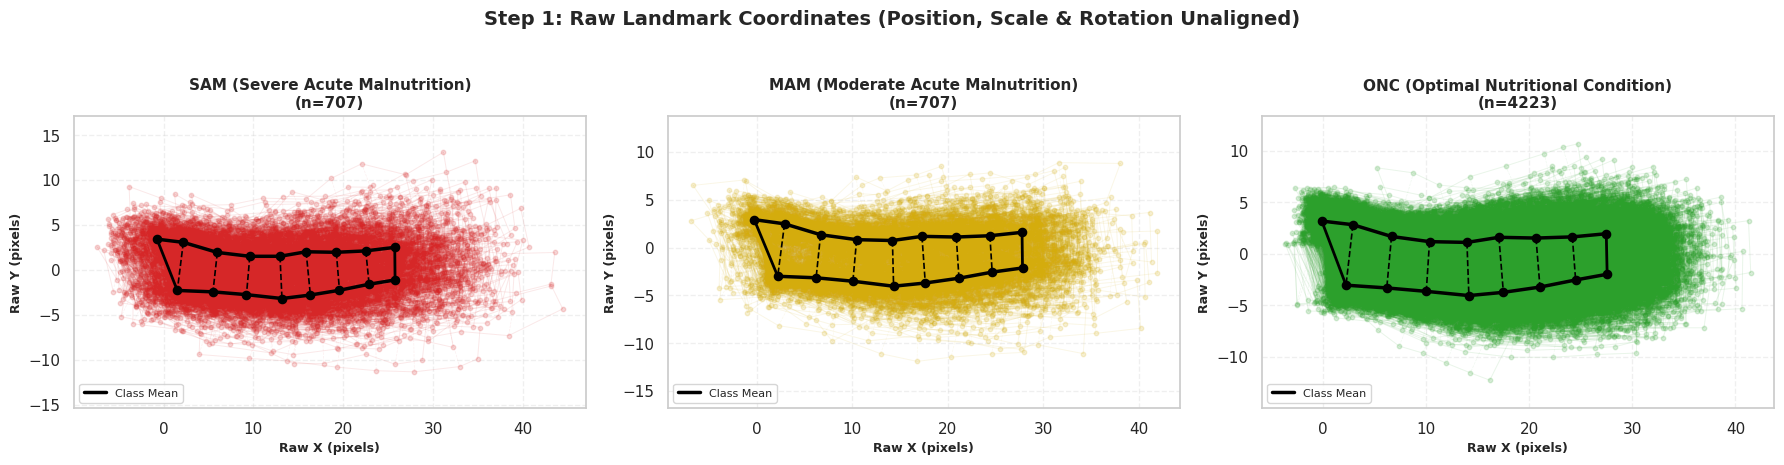

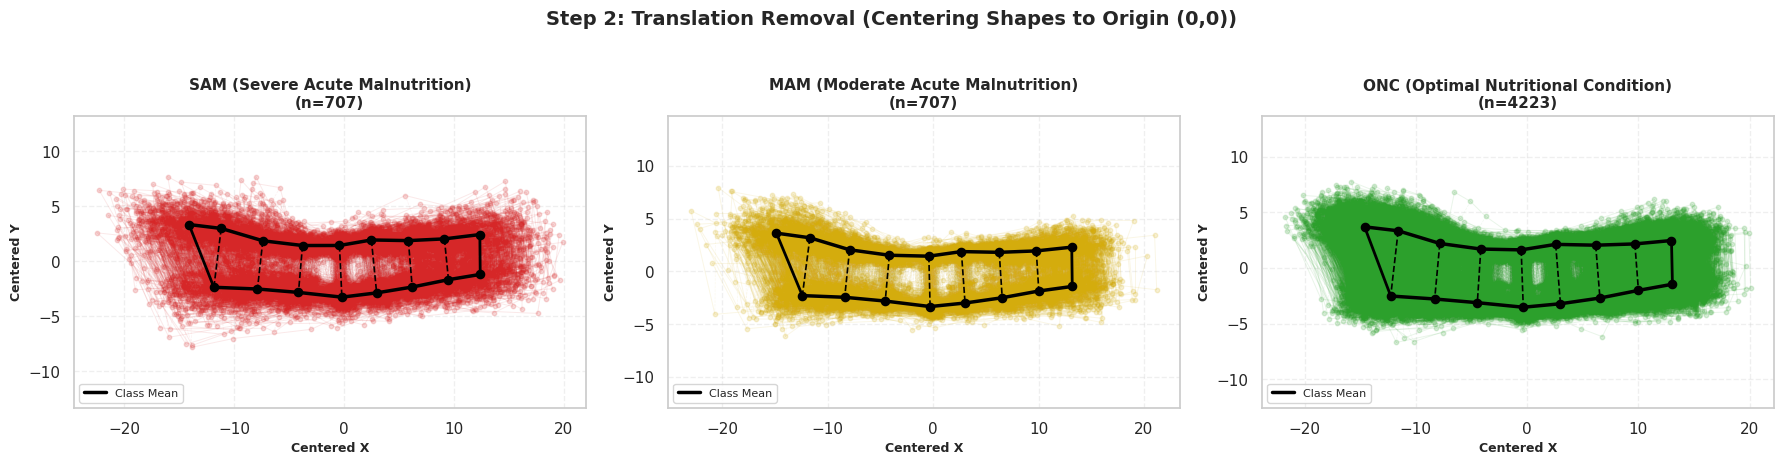

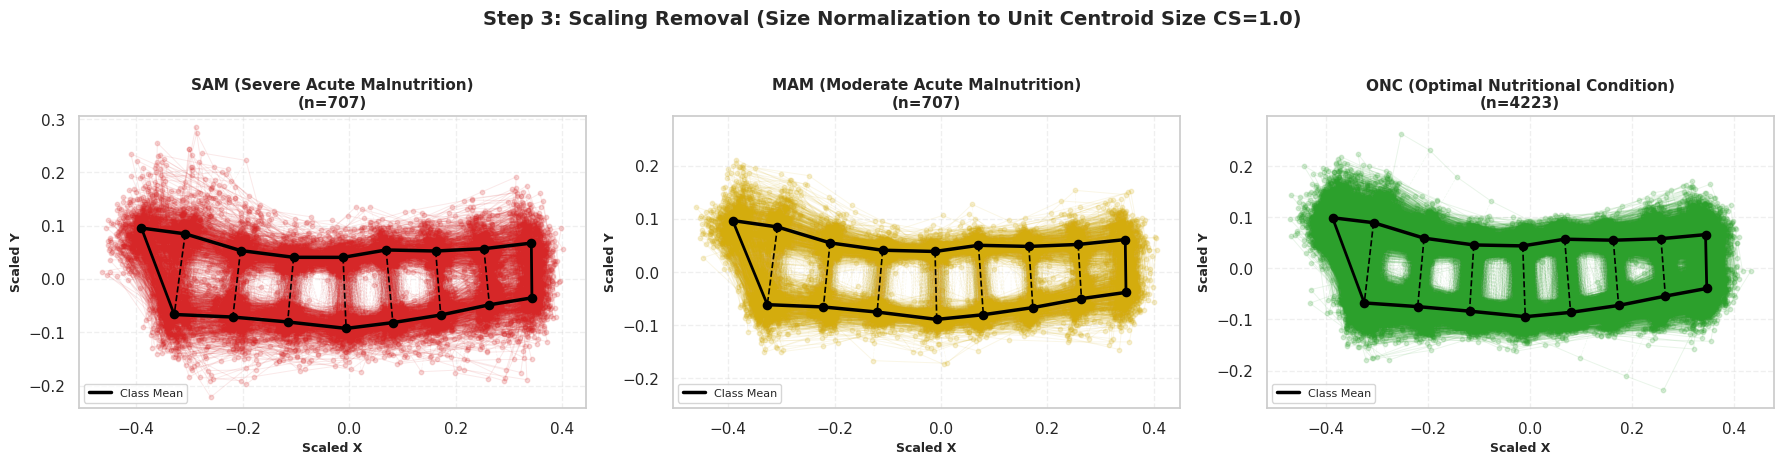

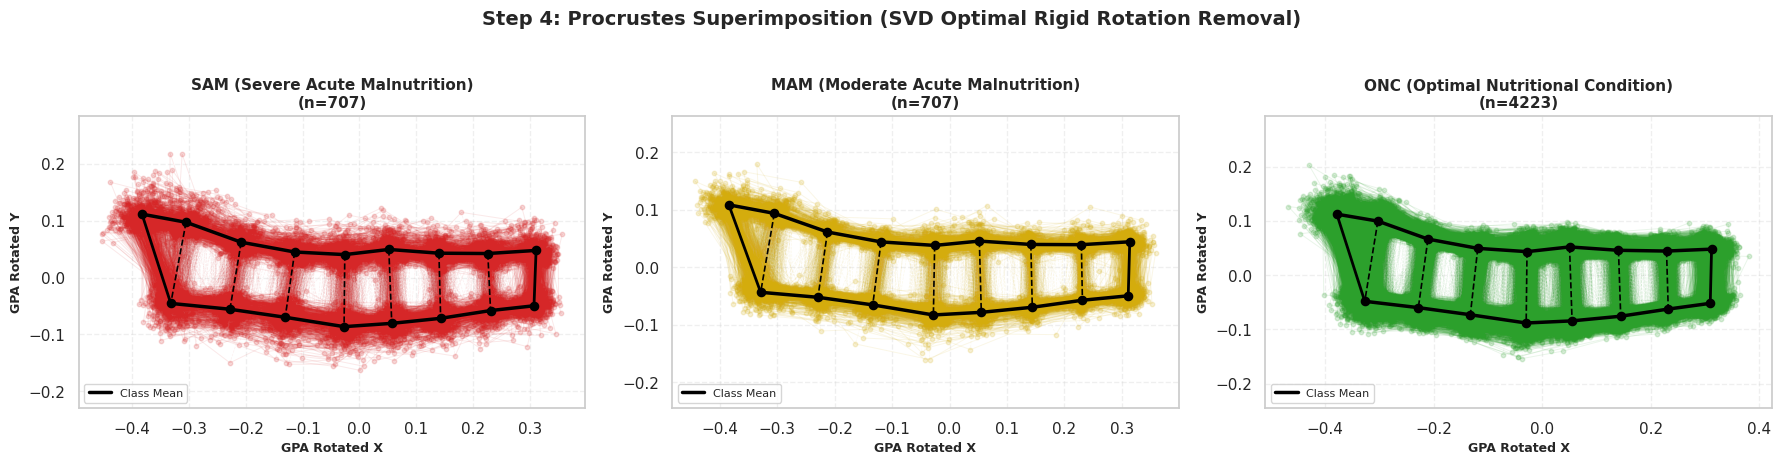

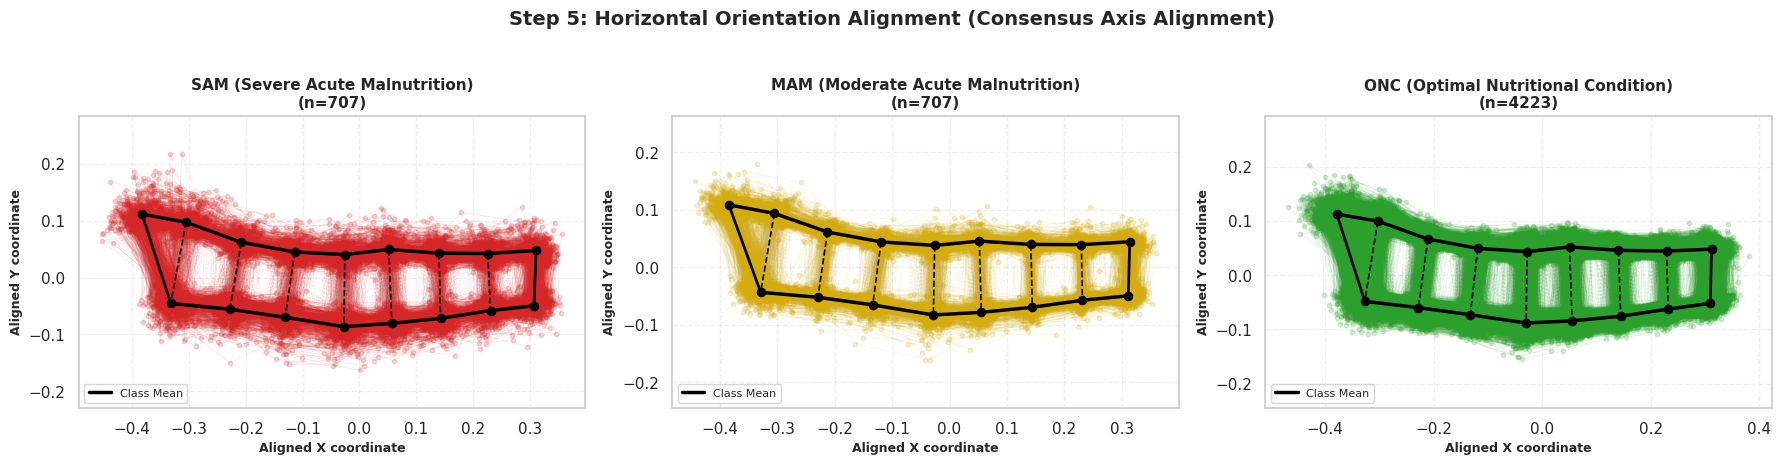

In [5]:
# Step-by-Step GPA Operations Visual Demonstration
classes = ['sam', 'mam', 'onc']
class_titles = {'sam': 'SAM (Severe Acute Malnutrition)', 'mam': 'MAM (Moderate Acute Malnutrition)', 'onc': 'ONC (Optimal Nutritional Condition)'}
class_colors = {'sam': '#d62728', 'mam': '#d4ac0d', 'onc': '#2ca02c'}

# Prepare data containers for each of the 5 GPA steps
raw_shapes = {}
centered_shapes = {}
scaled_shapes = {}
gpa_shapes = {}
horiz_shapes = {}

for cls in classes:
    df_cls = df_train_raw[df_train_raw['Class_Type'] == cls]
    N = len(df_cls)
    sh_raw = np.zeros((K, 2, N))
    sh_cent = np.zeros((K, 2, N))
    sh_scal = np.zeros((K, 2, N))
    sh_gpa = np.zeros((K, 2, N))
    
    for i in range(N):
        row = df_cls.iloc[i]
        for lid_idx, lid in enumerate(landmark_ids):
            sh_raw[lid_idx, 0, i] = row[f'X{lid}']
            sh_raw[lid_idx, 1, i] = row[f'Y{lid}']
            
            gx = f'GPA_X{lid}' if f'GPA_X{lid}' in row else f'X{lid}'
            gy = f'GPA_Y{lid}' if f'GPA_Y{lid}' in row else f'Y{lid}'
            sh_gpa[lid_idx, 0, i] = row[gx]
            sh_gpa[lid_idx, 1, i] = row[gy]
            
        c_sh, _ = center_shape(sh_raw[:, :, i])
        sh_cent[:, :, i] = c_sh
        s_sh, _ = scale_shape(c_sh)
        sh_scal[:, :, i] = s_sh
        
    raw_shapes[cls] = sh_raw
    centered_shapes[cls] = sh_cent
    scaled_shapes[cls] = sh_scal
    gpa_shapes[cls] = sh_gpa
    horiz_shapes[cls] = sh_gpa

steps_pipeline = [
    ("Step 1: Raw Landmark Coordinates (Position, Scale & Rotation Unaligned)", raw_shapes, "Raw X (pixels)", "Raw Y (pixels)"),
    ("Step 2: Translation Removal (Centering Shapes to Origin (0,0))", centered_shapes, "Centered X", "Centered Y"),
    ("Step 3: Scaling Removal (Size Normalization to Unit Centroid Size CS=1.0)", scaled_shapes, "Scaled X", "Scaled Y"),
    ("Step 4: Procrustes Superimposition (SVD Optimal Rigid Rotation Removal)", gpa_shapes, "GPA Rotated X", "GPA Rotated Y"),
    ("Step 5: Horizontal Orientation Alignment (Consensus Axis Alignment)", horiz_shapes, "Aligned X coordinate", "Aligned Y coordinate")
]

# Plot each step sequentially
for step_idx, (step_title, data_dict, xl, yl) in enumerate(steps_pipeline, 1):
    fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
    for j, cls in enumerate(classes):
        ax = axes[j]
        shapes_arr = data_dict[cls]
        N_s = shapes_arr.shape[2]
        mean_sh = np.mean(shapes_arr, axis=2)
        
        # Wireframe overlays
        for i in range(N_s):
            sh = shapes_arr[:, :, i]
            if upper_contour_idx:
                ax.plot(sh[upper_contour_idx, 0], sh[upper_contour_idx, 1], color=class_colors[cls], alpha=0.10, lw=0.7)
            if lower_contour_idx:
                ax.plot(sh[lower_contour_idx, 0], sh[lower_contour_idx, 1], color=class_colors[cls], alpha=0.10, lw=0.7)
            if shoulder_edge_idx:
                ax.plot(sh[shoulder_edge_idx, 0], sh[shoulder_edge_idx, 1], color=class_colors[cls], alpha=0.10, lw=0.7)
            if wrist_edge_idx:
                ax.plot(sh[wrist_edge_idx, 0], sh[wrist_edge_idx, 1], color=class_colors[cls], alpha=0.10, lw=0.7)
            for seg in dashed_cross_idx:
                ax.plot(sh[seg, 0], sh[seg, 1], color=class_colors[cls], alpha=0.07, lw=0.5, linestyle='--')
                
        # Landmark scatter
        ax.scatter(shapes_arr[:, 0, :].flatten(), shapes_arr[:, 1, :].flatten(), color=class_colors[cls], alpha=0.18, s=10)
        
        # Mean wireframe overlay
        if upper_contour_idx:
            ax.plot(mean_sh[upper_contour_idx, 0], mean_sh[upper_contour_idx, 1], color='black', lw=2.5, label='Class Mean')
        if lower_contour_idx:
            ax.plot(mean_sh[lower_contour_idx, 0], mean_sh[lower_contour_idx, 1], color='black', lw=2.5)
        if shoulder_edge_idx:
            ax.plot(mean_sh[shoulder_edge_idx, 0], mean_sh[shoulder_edge_idx, 1], color='black', lw=2.0)
        if wrist_edge_idx:
            ax.plot(mean_sh[wrist_edge_idx, 0], mean_sh[wrist_edge_idx, 1], color='black', lw=2.0)
        for seg in dashed_cross_idx:
            ax.plot(mean_sh[seg, 0], mean_sh[seg, 1], color='black', lw=1.2, linestyle='--')
        if len(midline_idx) >= 2:
            ax.plot(mean_sh[midline_idx, 0], mean_sh[midline_idx, 1], color='gold', lw=1.5, linestyle=':')
            
        ax.scatter(mean_sh[:, 0], mean_sh[:, 1], color='black', s=35, zorder=6)
        
        ax.set_title(f"{class_titles[cls]}\n(n={N_s})", fontsize=11, fontweight='bold')
        ax.set_xlabel(xl, fontsize=9, fontweight='bold')
        ax.set_ylabel(yl, fontsize=9, fontweight='bold')
        ax.grid(True, linestyle='--', alpha=0.3)
        ax.legend(loc='lower left', fontsize=8)
        ax.axis('equal')
        
    plt.suptitle(step_title, fontsize=14, fontweight='bold', y=1.03)
    plt.tight_layout()
    plt.show()

## Section 3: Data Matrix Setup & Class Sample Balancing
We prepare the **Training Matrix** (`X_train`, `y_train`) using **707 ONC, 707 MAM, and 707 SAM** specimens from the Geometric Augmented dataset, and the **Out-of-Sample Testing Matrix** (`X_test`, `y_test`) using **707 ONC, 707 MAM, and 217 SAM** specimens from the Pristine Real dataset.

In [6]:
# Create Balanced Training Matrix and Pristine Out-of-Sample Testing Matrix
target_col = 'Class_Type'

# 1. Training Subset (707 SAM, 707 MAM, 707 ONC)
df_tr_sam = df_train_raw[df_train_raw[target_col] == 'sam']
df_tr_mam = df_train_raw[df_train_raw[target_col] == 'mam']
df_tr_onc = df_train_raw[df_train_raw[target_col] == 'onc'].sample(n=min(707, len(df_train_raw[df_train_raw[target_col] == 'onc'])), random_state=RANDOM_STATE)

df_train_bal = pd.concat([df_tr_onc, df_tr_mam, df_tr_sam]).sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)

# 2. Testing Subset (217 SAM, 707 MAM, 707 ONC)
df_te_sam = df_test_raw[df_test_raw[target_col] == 'sam']
df_te_mam = df_test_raw[df_test_raw[target_col] == 'mam']
df_te_onc = df_test_raw[df_test_raw[target_col] == 'onc'].sample(n=min(707, len(df_test_raw[df_test_raw[target_col] == 'onc'])), random_state=RANDOM_STATE)

df_test_bal = pd.concat([df_te_onc, df_te_mam, df_te_sam]).sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)

# Select GPA coordinate columns excluding redundant Landmarks 2 and 3
gpa_cols = []
for lm in landmark_ids:
    gpa_cols.extend([f'GPA_X{lm}', f'GPA_Y{lm}'])

# Compute Allometric Size Correction (Shape Residuals)
df_tr_res, df_te_res, res_cols = compute_allometric_residuals_df(df_train_bal, df_test_bal, gpa_cols)

# Attach residual columns back to balanced dataframes
for col in res_cols:
    df_train_bal[col] = df_tr_res[col]
    df_test_bal[col] = df_te_res[col]

# Feature Set: Strictly the direct Allometric Shape Residual Coordinates (Excluding LM2 and LM3)
feature_cols = res_cols

X_train = df_train_bal[feature_cols].values
y_train = df_train_bal[target_col].values

X_test = df_test_bal[feature_cols].values
y_test = df_test_bal[target_col].values

# Numerical label encoding for classifiers requiring numeric targets (e.g., XGBoost)
label_map = {'sam': 0, 'mam': 1, 'onc': 2}
y_train_num = np.array([label_map[y] for y in y_train])
y_test_num = np.array([label_map[y] for y in y_test])

# Global variables for downstream feature visualization
X_gpa_bal = X_train
y_bal = y_train
df_gpa_balanced = df_train_bal

print("="*70)
print("EXPERIMENT MATRIX SETUP (ALLOMETRIC RESIDUAL FEATURE SPACE EXCL LM2 & LM3)")
print("="*70)
print(f"Training Matrix Shape: {X_train.shape} | Features: {len(feature_cols)} (Allometric Residual Coordinates)")
print(df_train_bal[target_col].value_counts().to_dict())

print(f"Testing & Validation Matrix Shape: {X_test.shape} | Features: {len(feature_cols)} (Allometric Residual Coordinates)")
print(df_test_bal[target_col].value_counts().to_dict())
print(f"Feature List ({len(feature_cols)} variables): {feature_cols}")


EXPERIMENT MATRIX SETUP (ALLOMETRIC RESIDUAL FEATURE SPACE EXCL LM2 & LM3)
Training Matrix Shape: (2121, 34) | Features: 34 (Allometric Residual Coordinates)
{'sam': 707, 'onc': 707, 'mam': 707}
Testing & Validation Matrix Shape: (891, 34) | Features: 34 (Allometric Residual Coordinates)
{'onc': 707, 'mam': 141, 'sam': 43}
Feature List (34 variables): ['Res_X1', 'Res_Y1', 'Res_X4', 'Res_Y4', 'Res_X5', 'Res_Y5', 'Res_X6', 'Res_Y6', 'Res_X7', 'Res_Y7', 'Res_X8', 'Res_Y8', 'Res_X9', 'Res_Y9', 'Res_X10', 'Res_Y10', 'Res_X12', 'Res_Y12', 'Res_X13', 'Res_Y13', 'Res_X14', 'Res_Y14', 'Res_X15', 'Res_Y15', 'Res_X16', 'Res_Y16', 'Res_X17', 'Res_Y17', 'Res_X18', 'Res_Y18', 'Res_X19', 'Res_Y19', 'Res_X20', 'Res_Y20']


## Section 3.1: Comparative Sequential Arm Wireframe Transformations (Augmented Training vs Pristine Real Datasets)

Prior to model training, we visually track and compare the step-by-step transformation of 2D anatomical arm landmark wireframes across all three classes (**SAM**, **MAM**, **ONC**) for both the **Geometric Augmented Training Dataset** and the **Pristine Real Testing Dataset**.

We plot **4 sequential 2x3 comparison grids**:
1. **STEP 1: Raw Arm Landmark Coordinates & Full Wireframe Grids (Before Alignment)** — Raw unaligned position, scale, and $360^\circ$ synthetic SAM rotational scatter across all classes.
2. **STEP 2: Centered Landmark Scatter Plot & Wireframes (Translation Removed)** — Shapes centered at origin $(0,0)$ by subtracting centroid $(\bar{X}, \bar{Y})$.
3. **STEP 3: Scaled Landmark Scatter Plot & Wireframes (Centroid Size Normalized $CS=1.0$)** — Shapes normalized by Centroid Size ($CS = \sqrt{\sum ((X_i - \bar{X})^2 + (Y_i - \bar{Y})^2)}$).
4. **STEP 4: Full GPA Aligned Landmark Scatter Plot & Wireframes (Translation, Scale & SVD Rotation Removed)** — Procrustes SVD rigid rotation and horizontally aligned wireframes with consensus mean overlays (`LM1` .. `LM20`).

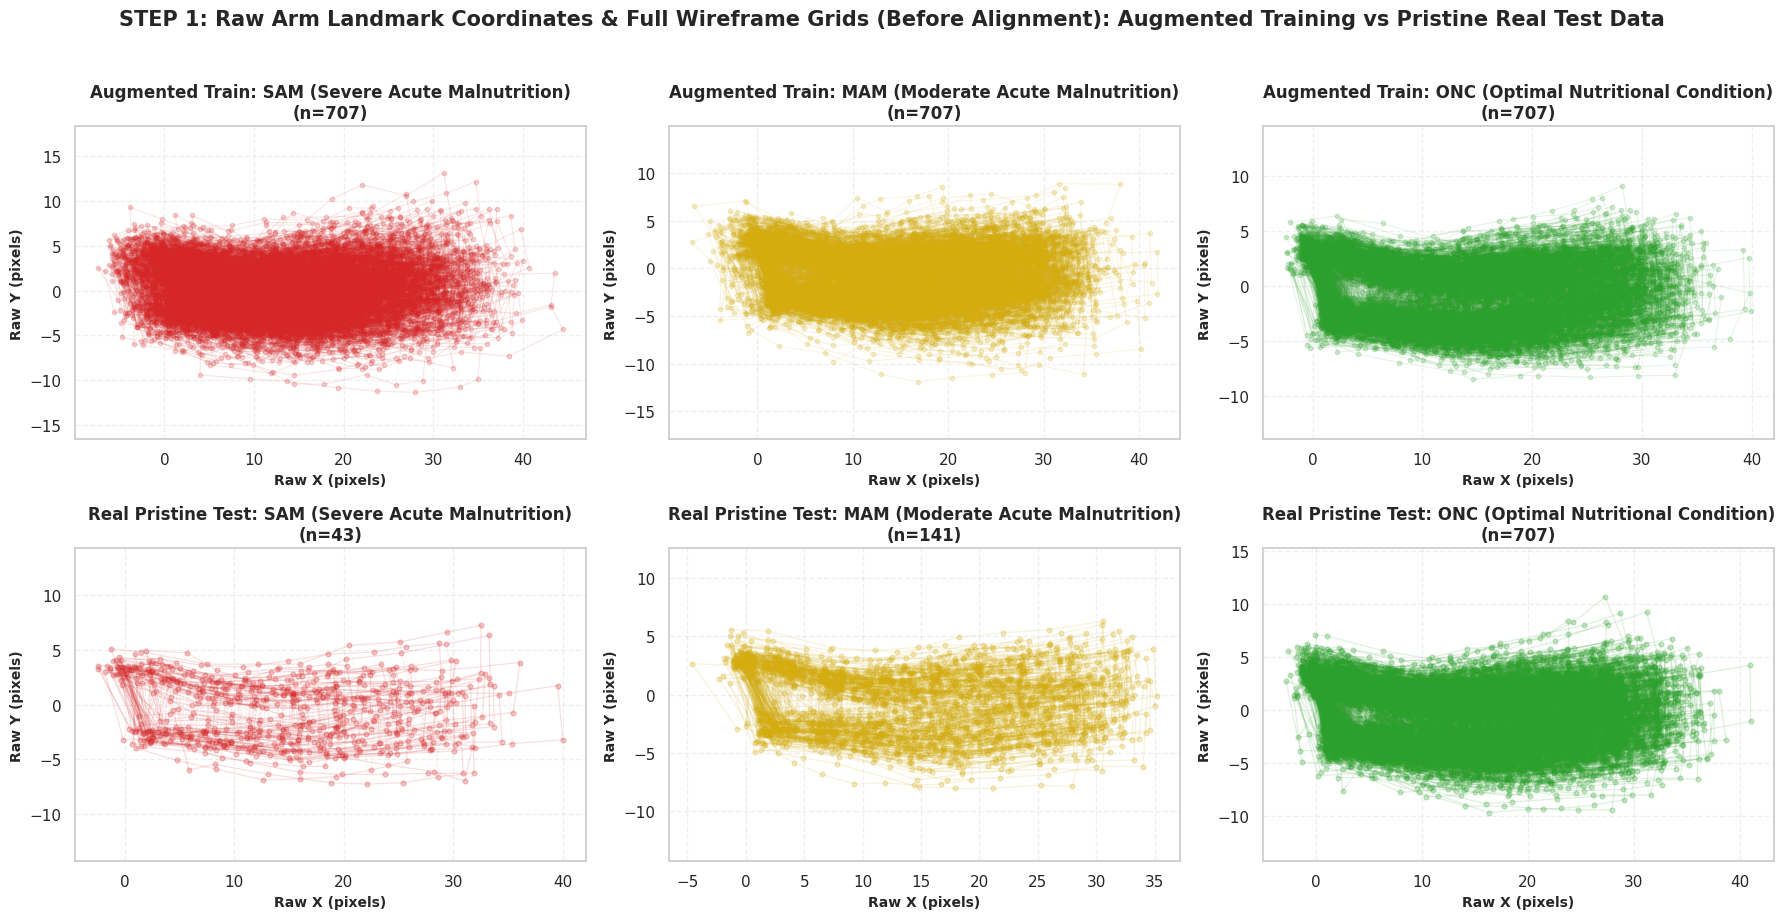

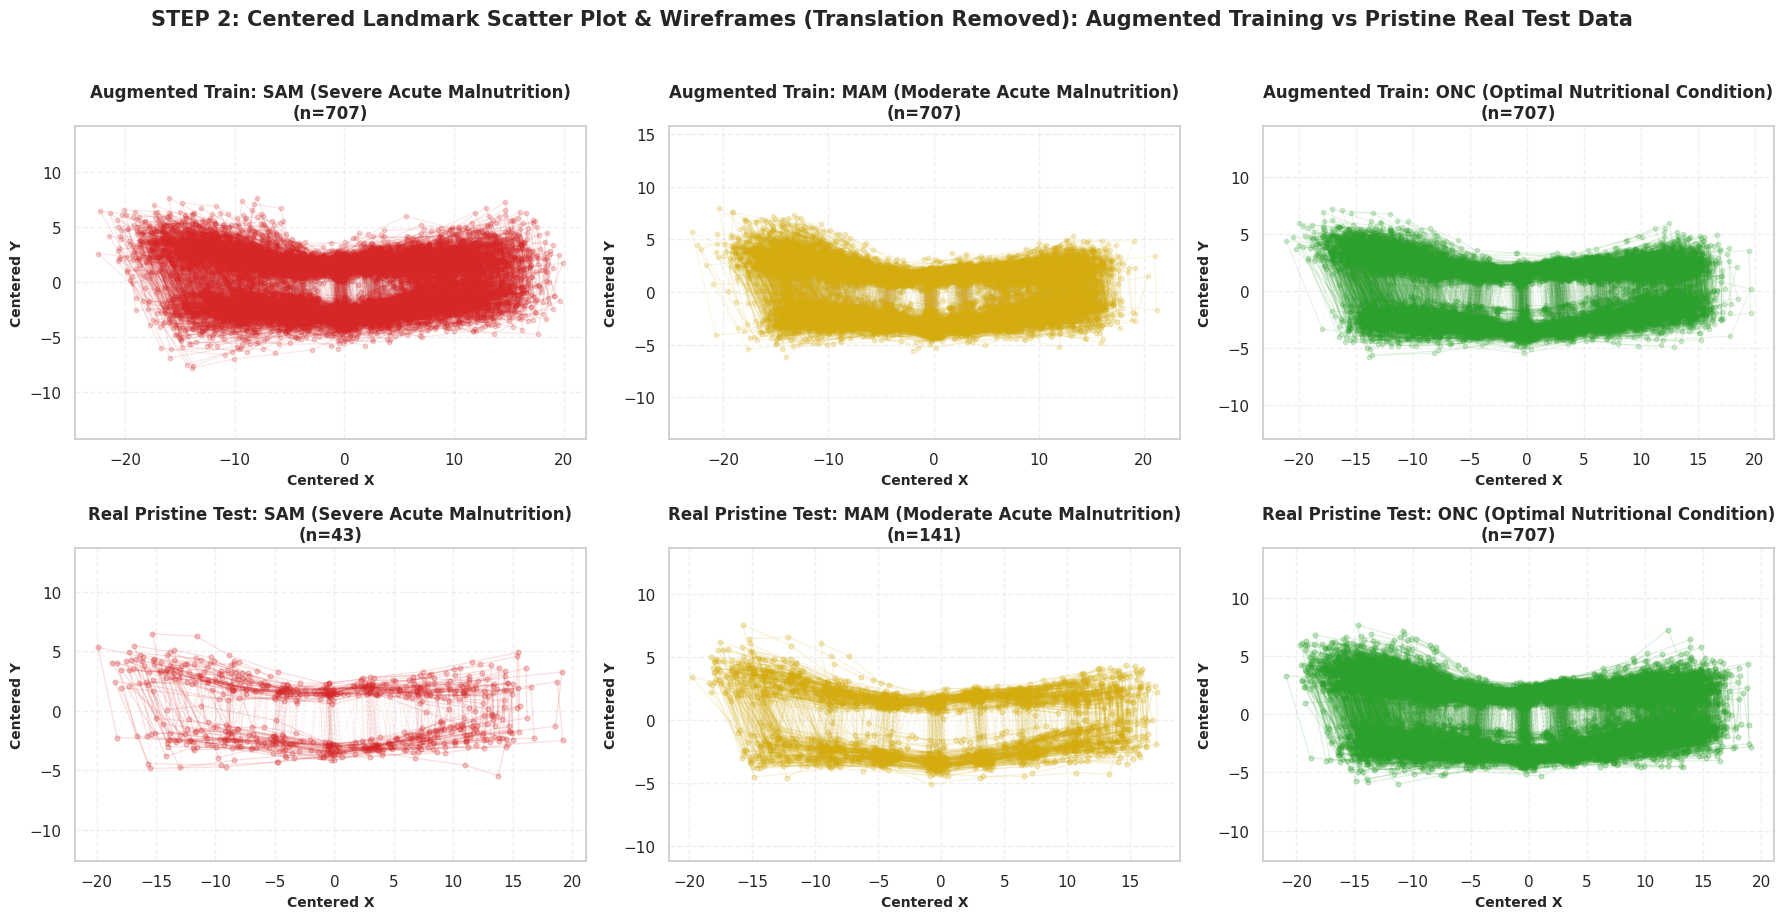

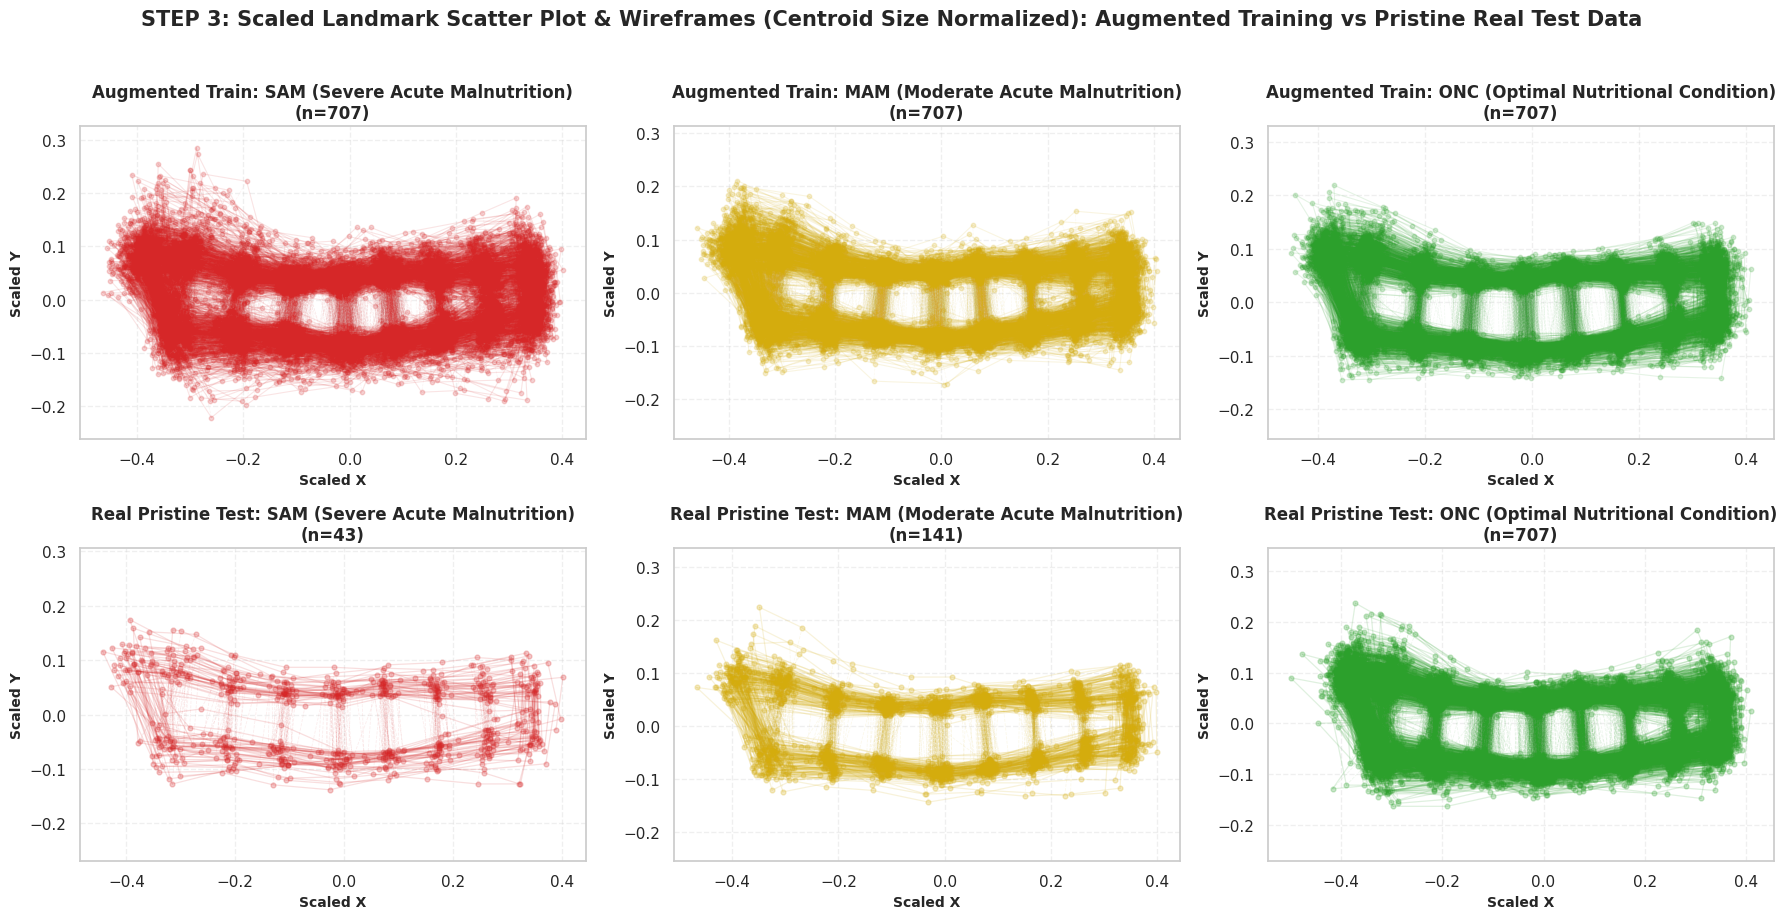

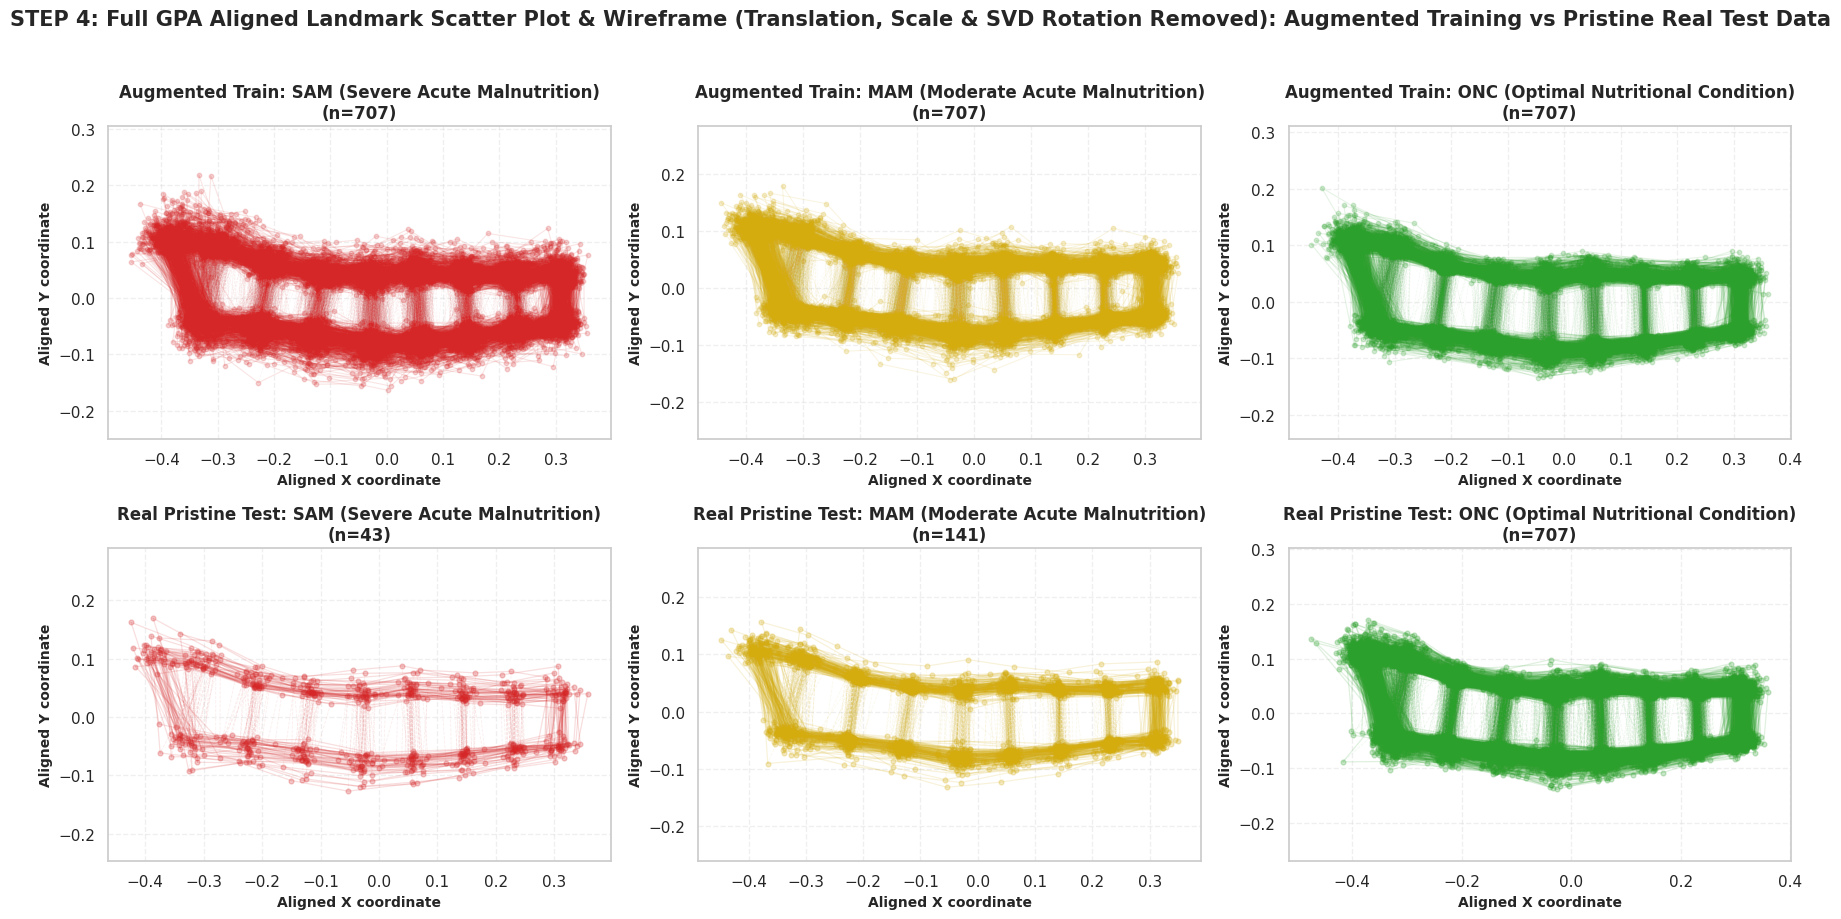

In [7]:
# Step-by-Step Wireframe Grid Transformations (Augmented Training vs Real Pristine)
classes = ['sam', 'mam', 'onc']
class_titles = {
    'sam': 'SAM (Severe Acute Malnutrition)',
    'mam': 'MAM (Moderate Acute Malnutrition)',
    'onc': 'ONC (Optimal Nutritional Condition)'
}
class_colors = {'sam': '#d62728', 'mam': '#d4ac0d', 'onc': '#2ca02c'}

def extract_transform_shapes(df_sub):
    N = len(df_sub)
    sh_raw = np.zeros((K, 2, N))
    sh_cent = np.zeros((K, 2, N))
    sh_scal = np.zeros((K, 2, N))
    sh_gpa = np.zeros((K, 2, N))
    
    for i in range(N):
        row = df_sub.iloc[i]
        for lid_idx, lid in enumerate(landmark_ids):
            sh_raw[lid_idx, 0, i] = row[f'X{lid}']
            sh_raw[lid_idx, 1, i] = row[f'Y{lid}']
            
            gx = f'GPA_X{lid}' if f'GPA_X{lid}' in row else f'X{lid}'
            gy = f'GPA_Y{lid}' if f'GPA_Y{lid}' in row else f'Y{lid}'
            sh_gpa[lid_idx, 0, i] = row[gx]
            sh_gpa[lid_idx, 1, i] = row[gy]
            
        c_sh, _ = center_shape(sh_raw[:, :, i])
        sh_cent[:, :, i] = c_sh
        s_sh, _ = scale_shape(c_sh)
        sh_scal[:, :, i] = s_sh
        
    return {'raw': sh_raw, 'centered': sh_cent, 'scaled': sh_scal, 'gpa': sh_gpa}

# Extract shapes for all classes
tr_step_shapes = {cls: extract_transform_shapes(df_train_bal[df_train_bal['Class_Type'] == cls]) for cls in classes}
te_step_shapes = {cls: extract_transform_shapes(df_test_bal[df_test_bal['Class_Type'] == cls]) for cls in classes}

grid_steps_config = [
    ('raw', 'STEP 1: Raw Arm Landmark Coordinates & Full Wireframe Grids (Before Alignment)', 'Raw X (pixels)', 'Raw Y (pixels)'),
    ('centered', 'STEP 2: Centered Landmark Scatter Plot & Wireframes (Translation Removed)', 'Centered X', 'Centered Y'),
    ('scaled', 'STEP 3: Scaled Landmark Scatter Plot & Wireframes (Centroid Size Normalized)', 'Scaled X', 'Scaled Y'),
    ('gpa', 'STEP 4: Full GPA Aligned Landmark Scatter Plot & Wireframe (Translation, Scale & SVD Rotation Removed)', 'Aligned X coordinate', 'Aligned Y coordinate')
]

for step_key, step_title, xl, yl in grid_steps_config:
    fig, axes = plt.subplots(2, 3, figsize=(18, 9))
    
    # Row 1: Augmented Training Data
    for j, cls in enumerate(classes):
        ax = axes[0, j]
        shapes_arr = tr_step_shapes[cls][step_key]
        plot_arm_wireframe(ax, shapes_arr, color=class_colors[cls], alpha_solid=0.12, alpha_dashed=0.06, lw_solid=0.8, lw_dashed=0.5, alpha_scatter=0.20, s=10, show_labels=False)
        title_str = f"Augmented Train: {class_titles[cls]}\n(n={shapes_arr.shape[2]})"
        ax.set_title(title_str, fontsize=12, fontweight='bold')
        ax.set_xlabel(xl, fontsize=10, fontweight='bold')
        ax.set_ylabel(yl, fontsize=10, fontweight='bold')
        ax.grid(True, linestyle='--', alpha=0.3)
        ax.axis('equal')
        
    # Row 2: Pristine Real Test Data
    for j, cls in enumerate(classes):
        ax = axes[1, j]
        shapes_arr = te_step_shapes[cls][step_key]
        plot_arm_wireframe(ax, shapes_arr, color=class_colors[cls], alpha_solid=0.15, alpha_dashed=0.08, lw_solid=0.9, lw_dashed=0.6, alpha_scatter=0.25, s=12, show_labels=False)
        title_str = f"Real Pristine Test: {class_titles[cls]}\n(n={shapes_arr.shape[2]})"
        ax.set_title(title_str, fontsize=12, fontweight='bold')
        ax.set_xlabel(xl, fontsize=10, fontweight='bold')
        ax.set_ylabel(yl, fontsize=10, fontweight='bold')
        ax.grid(True, linestyle='--', alpha=0.3)
        ax.axis('equal')
        
    plt.suptitle(f"{step_title}: Augmented Training vs Pristine Real Test Data", fontsize=15, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

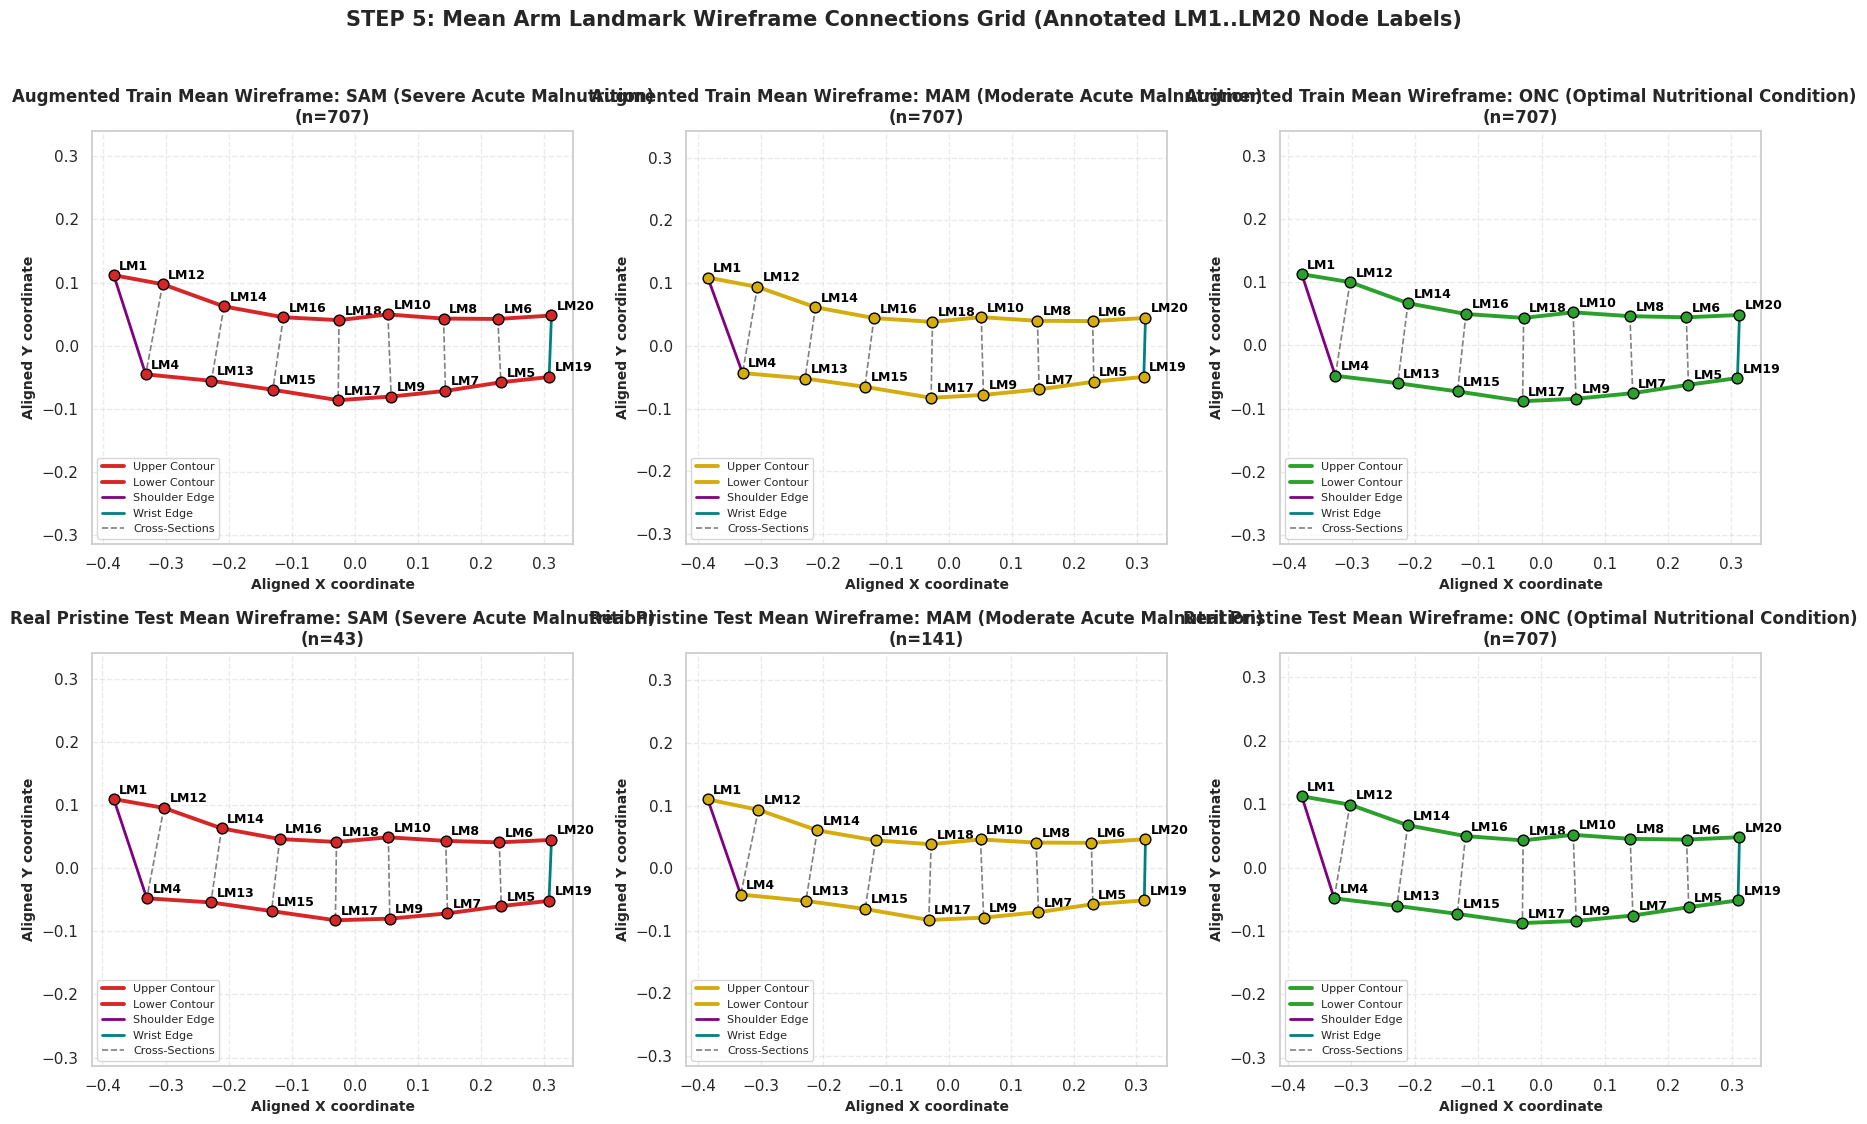

In [8]:
# STEP 5: Mean Arm Landmark Wireframe Connections Grid (Annotated LM1..LM20 Node Labels)
fig, axes = plt.subplots(2, 3, figsize=(18, 11))

# Row 1: Augmented Training Dataset Mean Shapes
for j, cls in enumerate(classes):
    ax = axes[0, j]
    shapes_arr = tr_step_shapes[cls]['gpa']
    mean_shape = np.mean(shapes_arr, axis=2)
    
    if upper_contour_idx:
        ax.plot(mean_shape[upper_contour_idx, 0], mean_shape[upper_contour_idx, 1], color=class_colors[cls], linewidth=2.8, label='Upper Contour', zorder=5)
    if lower_contour_idx:
        ax.plot(mean_shape[lower_contour_idx, 0], mean_shape[lower_contour_idx, 1], color=class_colors[cls], linewidth=2.8, label='Lower Contour', zorder=5)
    if shoulder_edge_idx:
        ax.plot(mean_shape[shoulder_edge_idx, 0], mean_shape[shoulder_edge_idx, 1], color='purple', linewidth=2.0, label='Shoulder Edge', zorder=5)
    if wrist_edge_idx:
        ax.plot(mean_shape[wrist_edge_idx, 0], mean_shape[wrist_edge_idx, 1], color='teal', linewidth=2.0, label='Wrist Edge', zorder=5)
    for idx_seg, seg in enumerate(dashed_cross_idx):
        lbl = 'Cross-Sections' if idx_seg == 0 else None
        ax.plot(mean_shape[seg, 0], mean_shape[seg, 1], color='gray', linewidth=1.2, linestyle='--', label=lbl, zorder=4)
    if len(midline_idx) >= 2:
        ax.plot(mean_shape[midline_idx, 0], mean_shape[midline_idx, 1], color='gold', linewidth=1.8, linestyle=':', label='Central Axis', zorder=4)
        
    ax.scatter(mean_shape[:, 0], mean_shape[:, 1], color=class_colors[cls], s=60, edgecolors='black', linewidth=1.0, zorder=6)
    
    for idx, lid in enumerate(landmark_ids):
        ax.annotate(f'LM{lid}', (mean_shape[idx, 0], mean_shape[idx, 1]), xytext=(4, 4), textcoords='offset points', fontsize=9, fontweight='bold', color='black')

    title_str = f"Augmented Train Mean Wireframe: {class_titles[cls]}\n(n={shapes_arr.shape[2]})"
    ax.set_title(title_str, fontsize=12, fontweight='bold')
    ax.set_xlabel('Aligned X coordinate', fontsize=10, fontweight='bold')
    ax.set_ylabel('Aligned Y coordinate', fontsize=10, fontweight='bold')
    ax.grid(True, linestyle='--', alpha=0.4)
    ax.legend(loc='lower left', fontsize=8)
    ax.axis('equal')

# Row 2: Real Pristine Testing Dataset Mean Shapes
for j, cls in enumerate(classes):
    ax = axes[1, j]
    shapes_arr = te_step_shapes[cls]['gpa']
    mean_shape = np.mean(shapes_arr, axis=2)
    
    if upper_contour_idx:
        ax.plot(mean_shape[upper_contour_idx, 0], mean_shape[upper_contour_idx, 1], color=class_colors[cls], linewidth=2.8, label='Upper Contour', zorder=5)
    if lower_contour_idx:
        ax.plot(mean_shape[lower_contour_idx, 0], mean_shape[lower_contour_idx, 1], color=class_colors[cls], linewidth=2.8, label='Lower Contour', zorder=5)
    if shoulder_edge_idx:
        ax.plot(mean_shape[shoulder_edge_idx, 0], mean_shape[shoulder_edge_idx, 1], color='purple', linewidth=2.0, label='Shoulder Edge', zorder=5)
    if wrist_edge_idx:
        ax.plot(mean_shape[wrist_edge_idx, 0], mean_shape[wrist_edge_idx, 1], color='teal', linewidth=2.0, label='Wrist Edge', zorder=5)
    for idx_seg, seg in enumerate(dashed_cross_idx):
        lbl = 'Cross-Sections' if idx_seg == 0 else None
        ax.plot(mean_shape[seg, 0], mean_shape[seg, 1], color='gray', linewidth=1.2, linestyle='--', label=lbl, zorder=4)
    if len(midline_idx) >= 2:
        ax.plot(mean_shape[midline_idx, 0], mean_shape[midline_idx, 1], color='gold', linewidth=1.8, linestyle=':', label='Central Axis', zorder=4)
        
    ax.scatter(mean_shape[:, 0], mean_shape[:, 1], color=class_colors[cls], s=60, edgecolors='black', linewidth=1.0, zorder=6)
    
    for idx, lid in enumerate(landmark_ids):
        ax.annotate(f'LM{lid}', (mean_shape[idx, 0], mean_shape[idx, 1]), xytext=(4, 4), textcoords='offset points', fontsize=9, fontweight='bold', color='black')

    title_str = f"Real Pristine Test Mean Wireframe: {class_titles[cls]}\n(n={shapes_arr.shape[2]})"
    ax.set_title(title_str, fontsize=12, fontweight='bold')
    ax.set_xlabel('Aligned X coordinate', fontsize=10, fontweight='bold')
    ax.set_ylabel('Aligned Y coordinate', fontsize=10, fontweight='bold')
    ax.grid(True, linestyle='--', alpha=0.4)
    ax.legend(loc='lower left', fontsize=8)
    ax.axis('equal')

plt.suptitle('STEP 5: Mean Arm Landmark Wireframe Connections Grid (Annotated LM1..LM20 Node Labels)', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

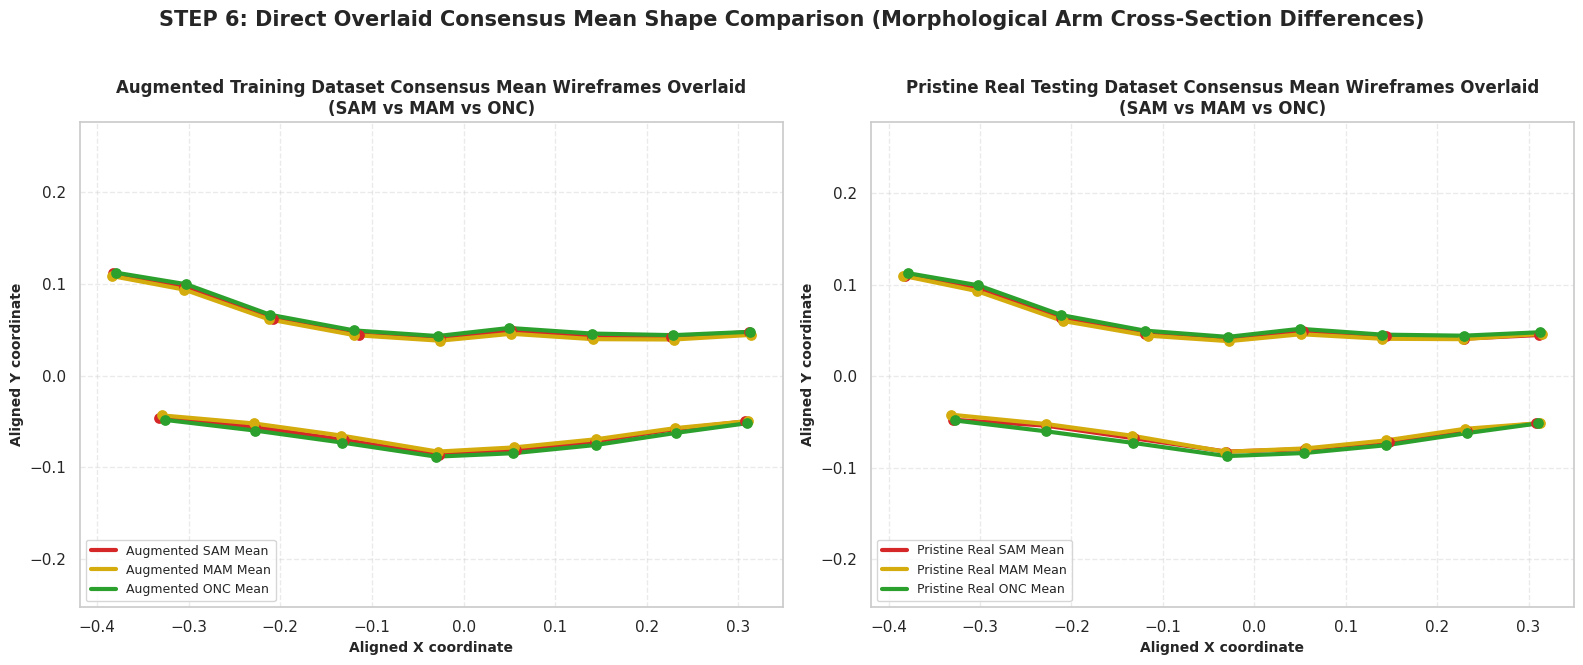

In [9]:
# STEP 6: Direct Overlaid Consensus Mean Shape Comparison (SAM vs MAM vs ONC)
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))

# Subplot 1: Augmented Training Dataset Mean Shapes Overlaid
ax = axes[0]
for cls in classes:
    m_sh = np.mean(tr_step_shapes[cls]['gpa'], axis=2)
    if upper_contour_idx:
        ax.plot(m_sh[upper_contour_idx, 0], m_sh[upper_contour_idx, 1], color=class_colors[cls], lw=3.0, label=f"Augmented {cls.upper()} Mean")
    if lower_contour_idx:
        ax.plot(m_sh[lower_contour_idx, 0], m_sh[lower_contour_idx, 1], color=class_colors[cls], lw=3.0)
    ax.scatter(m_sh[:, 0], m_sh[:, 1], color=class_colors[cls], s=45, zorder=6)

ax.set_title("Augmented Training Dataset Consensus Mean Wireframes Overlaid\n(SAM vs MAM vs ONC)", fontsize=12, fontweight='bold')
ax.set_xlabel('Aligned X coordinate', fontsize=10, fontweight='bold')
ax.set_ylabel('Aligned Y coordinate', fontsize=10, fontweight='bold')
ax.grid(True, linestyle='--', alpha=0.4)
ax.legend(loc='lower left', fontsize=9)
ax.axis('equal')

# Subplot 2: Real Pristine Testing Dataset Mean Shapes Overlaid
ax = axes[1]
for cls in classes:
    m_sh = np.mean(te_step_shapes[cls]['gpa'], axis=2)
    if upper_contour_idx:
        ax.plot(m_sh[upper_contour_idx, 0], m_sh[upper_contour_idx, 1], color=class_colors[cls], lw=3.0, label=f"Pristine Real {cls.upper()} Mean")
    if lower_contour_idx:
        ax.plot(m_sh[lower_contour_idx, 0], m_sh[lower_contour_idx, 1], color=class_colors[cls], lw=3.0)
    ax.scatter(m_sh[:, 0], m_sh[:, 1], color=class_colors[cls], s=45, zorder=6)

ax.set_title("Pristine Real Testing Dataset Consensus Mean Wireframes Overlaid\n(SAM vs MAM vs ONC)", fontsize=12, fontweight='bold')
ax.set_xlabel('Aligned X coordinate', fontsize=10, fontweight='bold')
ax.set_ylabel('Aligned Y coordinate', fontsize=10, fontweight='bold')
ax.grid(True, linestyle='--', alpha=0.4)
ax.legend(loc='lower left', fontsize=9)
ax.axis('equal')

plt.suptitle('STEP 6: Direct Overlaid Consensus Mean Shape Comparison (Morphological Arm Cross-Section Differences)', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## Section 4: Shape Space PCA & Multi-Dimensional Visualizations
We perform **Principal Component Analysis (PCA)** on the GPA-aligned shape features to project morphometric variation into lower-dimensional space and plot 2D shape space scatter plots.

PCA SHAPE SPACE EXPLAINED VARIANCE (TRAINING DATASET)
PC1: 22.84% variance explained (Cumulative: 22.84%)
PC2: 14.66% variance explained (Cumulative: 37.51%)
PC3: 9.29% variance explained (Cumulative: 46.80%)
PC4: 7.02% variance explained (Cumulative: 53.82%)
PC5: 5.44% variance explained (Cumulative: 59.26%)


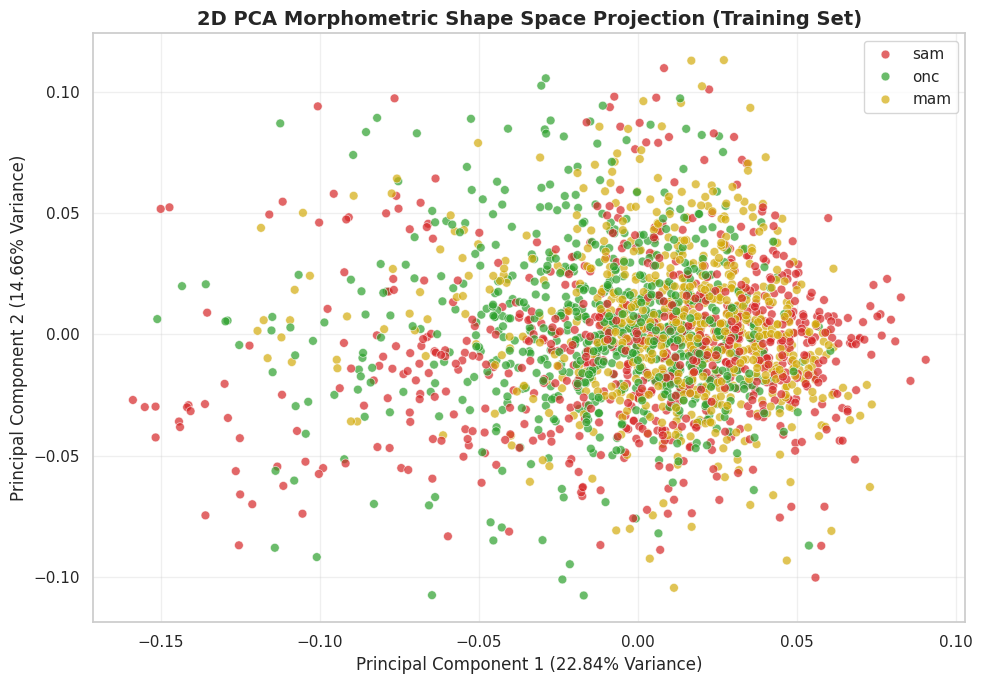

In [10]:
# Fit PCA on GPA landmark features
pca = PCA(n_components=10)
X_pca_train = pca.fit_transform(df_train_bal[gpa_cols].values)
var_exp = pca.explained_variance_ratio_ * 100

print("="*70)
print("PCA SHAPE SPACE EXPLAINED VARIANCE (TRAINING DATASET)")
print("="*70)
for i, v in enumerate(var_exp[:5], 1):
    print(f"PC{i}: {v:.2f}% variance explained (Cumulative: {np.sum(var_exp[:i]):.2f}%)")

# Plot 2D PCA Scatter Plot
fig, ax = plt.subplots(figsize=(10, 7))
sns.scatterplot(x=X_pca_train[:, 0], y=X_pca_train[:, 1], hue=y_train, palette={'sam': '#d62728', 'mam': '#d4ac0d', 'onc': '#2ca02c'}, alpha=0.7, s=40, ax=ax)
ax.set_title('2D PCA Morphometric Shape Space Projection (Training Set)', fontsize=14, fontweight='bold')
ax.set_xlabel(f'Principal Component 1 ({var_exp[0]:.2f}% Variance)', fontsize=12)
ax.set_ylabel(f'Principal Component 2 ({var_exp[1]:.2f}% Variance)', fontsize=12)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Section 5: Machine Learning Classifiers Overview & Architectural Comparison

We benchmark **8 Machine Learning Classifiers** across both 10-Fold Stratified Cross-Validation and Pristine Out-of-Sample Testing. Below is an overview of each classifier, including its theoretical foundation, key strengths, and inherent limitations for geometric morphometric classification:

---

### 1. 📈 Logistic Regression
* **Model Type**: Linear Parametric Discriminative Model.
* **Strengths**: Highly interpretable, fast computation, produces well-calibrated class probability estimates.
* **Limitations**: Assumes linear decision boundaries; vulnerable to multicollinearity among dense GPA coordinates.

### 2. 📐 Linear Discriminant Analysis (LDA)
* **Model Type**: Generative Linear Decision Boundary Classifier.
* **Strengths**: Statistically optimal when classes share a common covariance matrix; robust for well-separated morphometric clusters.
* **Limitations**: Assumes multivariate normal distribution per class; performance degrades under non-linear shape variations.

### 3. 🛡️ Support Vector Machine (SVM with RBF Kernel)
* **Model Type**: Non-Linear Maximum-Margin Kernel Classifier.
* **Strengths**: Highly effective in high-dimensional landmark spaces; kernel trick captures complex non-linear shape manifolds.
* **Limitations**: Computationally expensive for large sample sizes; highly sensitive to hyperparameter tuning ($C, \gamma$).

### 4. 🌲 Random Forest Classifier
* **Model Type**: Ensemble Bagging Decision Trees.
* **Strengths**: Non-parametric, resistant to overfitting via bootstrap aggregation, captures non-linear feature interactions, provides Gini feature importance.
* **Limitations**: Can create axis-aligned decision boundaries that over-segment smooth geometric variations.

### 5. 🌴 Extra Trees Classifier (Extremely Randomized Trees)
* **Model Type**: Randomized Ensemble Decision Trees.
* **Strengths**: Randomizes node split thresholds, reducing variance compared to standard Random Forest; highly efficient and robust.
* **Limitations**: Slightly higher bias than standard decision trees if split thresholds miss subtle landmark shifts.

### 6. 🚀 Gradient Boosting Classifier
* **Model Type**: Sequential Boosting Ensemble.
* **Strengths**: Iteratively minimizes residual classification errors step-by-step; yields high accuracy on subtle morphometric boundaries.
* **Limitations**: Sequential training makes it prone to overfitting if noisy landmark coordinates are present.

### 7. 🎯 k-Nearest Neighbors (k=5)
* **Model Type**: Non-Parametric Instance-Based Memory Model.
* **Strengths**: Simple, intuitive Euclidean shape-distance metric; no restrictive parametric assumptions.
* **Limitations**: Sensitive to local noise; impacted by the curse of dimensionality as landmark feature count grows.

### 8. ⚡ XGBoost Classifier (Extreme Gradient Boosting)
* **Model Type**: Optimized Scalable Regularized Tree Boosting.
* **Strengths**: Incorporates built-in $L_1$ and $L_2$ regularization to prevent overfitting, handles complex non-linear feature interactions, fast parallel execution, robust handling of skewed class proportions.
* **Limitations**: Higher memory footprint; requires hyperparameter tuning (learning rate, tree depth, subsampling).

## Section 6: Multi-Class Model Training & 10-Fold Stratified Cross-Validation

We evaluate **8 Machine Learning Classifiers** using 10-Fold Stratified Cross-Validation on the Augmented Training Dataset and test them out-of-sample on the Pristine Real Dataset (`final_cleaned_dataset_full.csv`).

Running 10-Fold Stratified Cross-Validation & Out-of-Sample Testing across 8 Classifiers...

8-CLASSIFIER BENCHMARK RESULTS (AUGMENTED TRAIN VS PRISTINE OUT-OF-SAMPLE TEST)
                       Model  10-Fold CV Acc (%)  10-Fold CV F1 (%)  OOS Test Acc (%)  OOS Test F1 (%)  OOS SAM Recall (%)  OOS SAM Precision (%)
      Extra Trees Classifier           69.071884          68.928098         71.043771        47.135097           11.627907              10.204082
               Random Forest           68.365001          68.059786         69.696970        47.827029           18.604651              10.958904
            SVM (RBF Kernel)           68.365666          68.388250         69.248036        44.869646            6.976744               7.317073
          XGBoost Classifier           66.102843          66.025923         68.911336        46.096643           13.953488              10.344828
           Gradient Boosting           65.678315          65.577205         68.125701        44.8

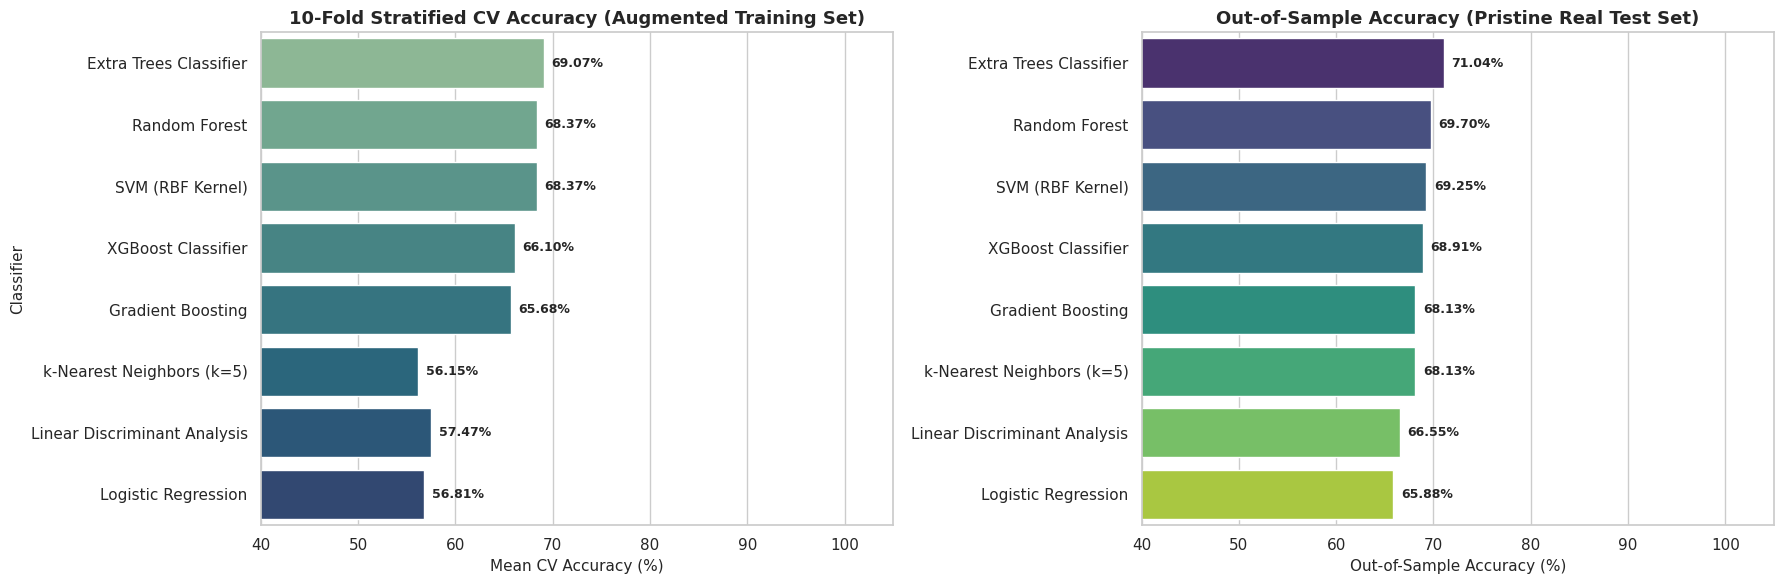

In [11]:
# Define All 8 Machine Learning Classifiers
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    'Linear Discriminant Analysis': LinearDiscriminantAnalysis(),
    'SVM (RBF Kernel)': SVC(kernel='rbf', probability=True, random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE),
    'Extra Trees Classifier': ExtraTreesClassifier(n_estimators=100, random_state=RANDOM_STATE),
    'Gradient Boosting': GradientBoostingClassifier(random_state=RANDOM_STATE),
    'k-Nearest Neighbors (k=5)': KNeighborsClassifier(n_neighbors=5),
    'XGBoost Classifier': XGBClassifier(objective='multi:softprob', eval_metric='mlogloss', n_estimators=100, learning_rate=0.1, max_depth=4, random_state=RANDOM_STATE)
}

skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
benchmark_results = []

print("Running 10-Fold Stratified Cross-Validation & Out-of-Sample Testing across 8 Classifiers...\n")

for name, clf in models.items():
    # 1. 10-Fold Cross-Validation on Augmented Training Dataset
    cv_accs, cv_f1s = [], []
    for tr_idx, val_idx in skf.split(X_train, y_train_num):
        scaler = StandardScaler()
        X_tr = scaler.fit_transform(X_train[tr_idx])
        X_va = scaler.transform(X_train[val_idx])
        
        clf.fit(X_tr, y_train_num[tr_idx])
        preds = clf.predict(X_va)
        
        cv_accs.append(accuracy_score(y_train_num[val_idx], preds))
        cv_f1s.append(f1_score(y_train_num[val_idx], preds, average='macro'))
        
    # 2. Out-of-Sample Testing on Pristine Real Dataset
    scaler_full = StandardScaler()
    X_tr_full = scaler_full.fit_transform(X_train)
    X_te_full = scaler_full.transform(X_test)
    
    clf.fit(X_tr_full, y_train_num)
    oos_preds = clf.predict(X_te_full)
    
    oos_acc = accuracy_score(y_test_num, oos_preds) * 100
    oos_f1 = f1_score(y_test_num, oos_preds, average='macro') * 100
    sam_rec = recall_score(y_test_num, oos_preds, labels=[0], average=None)[0] * 100
    sam_prec = precision_score(y_test_num, oos_preds, labels=[0], average=None, zero_division=0)[0] * 100
    
    benchmark_results.append({
        'Model': name,
        '10-Fold CV Acc (%)': np.mean(cv_accs) * 100,
        '10-Fold CV F1 (%)': np.mean(cv_f1s) * 100,
        'OOS Test Acc (%)': oos_acc,
        'OOS Test F1 (%)': oos_f1,
        'OOS SAM Recall (%)': sam_rec,
        'OOS SAM Precision (%)': sam_prec
    })

df_cv = pd.DataFrame(benchmark_results).sort_values(by='OOS Test Acc (%)', ascending=False).reset_index(drop=True)

print("="*100)
print("8-CLASSIFIER BENCHMARK RESULTS (AUGMENTED TRAIN VS PRISTINE OUT-OF-SAMPLE TEST)")
print("="*100)
print(df_cv.to_string(index=False))

# Plot Comparative Model Performance Bar Chart
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

sns.barplot(data=df_cv, x='10-Fold CV Acc (%)', y='Model', ax=axes[0], palette='crest')
axes[0].set_title('10-Fold Stratified CV Accuracy (Augmented Training Set)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Mean CV Accuracy (%)', fontsize=11)
axes[0].set_ylabel('Classifier', fontsize=11)
axes[0].set_xlim(40, 105)

for p in axes[0].patches:
    w = p.get_width()
    axes[0].annotate(f"{w:.2f}%", (w + 0.8, p.get_y() + p.get_height() / 2.), ha='left', va='center', fontweight='bold', fontsize=9)

sns.barplot(data=df_cv, x='OOS Test Acc (%)', y='Model', ax=axes[1], palette='viridis')
axes[1].set_title('Out-of-Sample Accuracy (Pristine Real Test Set)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Out-of-Sample Accuracy (%)', fontsize=11)
axes[1].set_ylabel('', fontsize=11)
axes[1].set_xlim(40, 105)

for p in axes[1].patches:
    w = p.get_width()
    axes[1].annotate(f"{w:.2f}%", (w + 0.8, p.get_y() + p.get_height() / 2.), ha='left', va='center', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.show()

## Section 7: Binary Sub-Class Classification Pipelines
We perform pairwise binary classifications (SAM vs ONC, SAM vs MAM, MAM vs ONC) to assess pair-wise morphometric discriminability and compute ROC-AUC curves using classifiers including XGBoost.

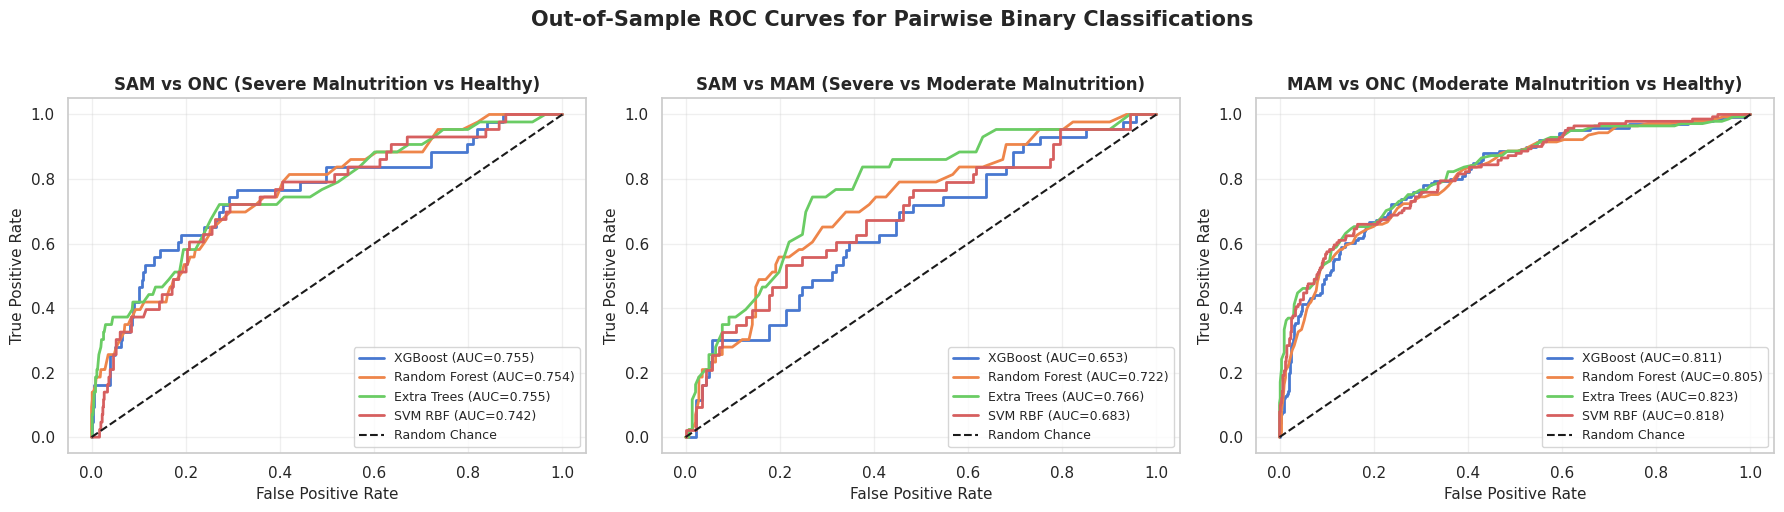

In [12]:
binary_pairs = [
    ('sam', 'onc', 'SAM vs ONC (Severe Malnutrition vs Healthy)'),
    ('sam', 'mam', 'SAM vs MAM (Severe vs Moderate Malnutrition)'),
    ('mam', 'onc', 'MAM vs ONC (Moderate Malnutrition vs Healthy)')
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (cls1, cls2, title) in zip(axes, binary_pairs):
    sub_df_tr = df_train_bal[df_train_bal['Class_Type'].isin([cls1, cls2])].copy()
    sub_df_te = df_test_bal[df_test_bal['Class_Type'].isin([cls1, cls2])].copy()
    
    X_tr_b = sub_df_tr[feature_cols].values
    y_tr_b = np.array([1 if y == cls1 else 0 for y in sub_df_tr['Class_Type']])
    
    X_te_b = sub_df_te[feature_cols].values
    y_te_b = np.array([1 if y == cls1 else 0 for y in sub_df_te['Class_Type']])
    
    scaler_b = StandardScaler()
    X_tr_b_s = scaler_b.fit_transform(X_tr_b)
    X_te_b_s = scaler_b.transform(X_te_b)
    
    b_models = {
        'XGBoost': XGBClassifier(n_estimators=100, max_depth=4, learning_rate=0.1, random_state=RANDOM_STATE, eval_metric='logloss'),
        'Random Forest': RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE),
        'Extra Trees': ExtraTreesClassifier(n_estimators=100, random_state=RANDOM_STATE),
        'SVM RBF': SVC(probability=True, random_state=RANDOM_STATE)
    }
    
    for mname, mobj in b_models.items():
        mobj.fit(X_tr_b_s, y_tr_b)
        probs = mobj.predict_proba(X_te_b_s)[:, 1]
        fpr, tpr, _ = roc_curve(y_te_b, probs)
        auc_score = roc_auc_score(y_te_b, probs)
        ax.plot(fpr, tpr, label=f"{mname} (AUC={auc_score:.3f})", linewidth=2)
        
    ax.plot([0, 1], [0, 1], 'k--', label='Random Chance')
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel('False Positive Rate', fontsize=11)
    ax.set_ylabel('True Positive Rate', fontsize=11)
    ax.legend(loc='lower right', fontsize=9)
    ax.grid(True, alpha=0.3)

plt.suptitle('Out-of-Sample ROC Curves for Pairwise Binary Classifications', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## Section 8: 2D PCA Decision Boundaries Visual Grid
We visualize 2D decision boundary spaces for top classifiers (including **XGBoost Classifier**, **Extra Trees**, **Random Forest**, and **Logistic Regression**) operating on the first two Principal Components.

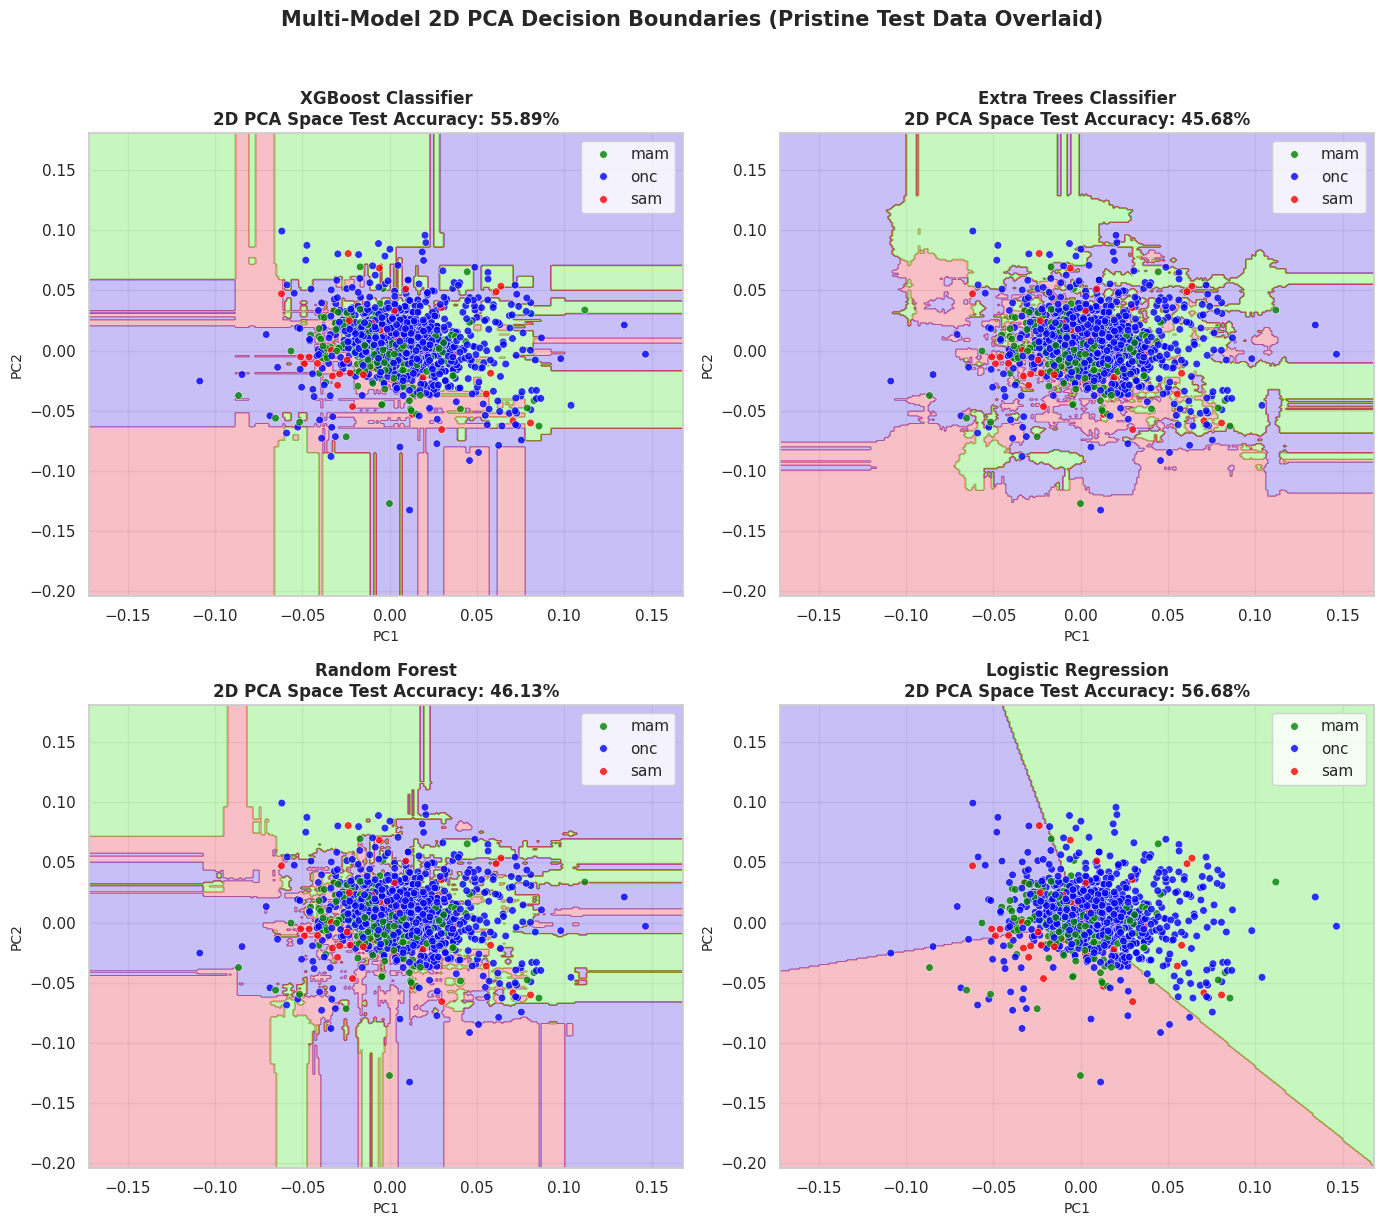

In [13]:
pca_2d = PCA(n_components=2)
X_train_pca2d = pca_2d.fit_transform(X_train)
X_test_pca2d = pca_2d.transform(X_test)

models_2d = {
    'XGBoost Classifier': XGBClassifier(objective='multi:softprob', eval_metric='mlogloss', n_estimators=100, max_depth=3, random_state=RANDOM_STATE),
    'Extra Trees Classifier': ExtraTreesClassifier(n_estimators=100, random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE),
    'Logistic Regression': LogisticRegression(random_state=RANDOM_STATE)
}

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.flatten()

x_min, x_max = X_train_pca2d[:, 0].min() - 0.05, X_train_pca2d[:, 0].max() + 0.05
y_min, y_max = X_train_pca2d[:, 1].min() - 0.05, X_train_pca2d[:, 1].max() + 0.05
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))

for ax, (mname, mclf) in zip(axes, models_2d.items()):
    mclf.fit(X_train_pca2d, y_train_num)
    Z = mclf.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    
    ax.contourf(xx, yy, Z, alpha=0.25, cmap='brg')
    sns.scatterplot(x=X_test_pca2d[:, 0], y=X_test_pca2d[:, 1], hue=y_test, palette={'sam': 'red', 'mam': 'green', 'onc': 'blue'}, s=30, alpha=0.8, ax=ax)
    
    title_str = f"{mname}\n2D PCA Space Test Accuracy: {accuracy_score(y_test_num, mclf.predict(X_test_pca2d))*100:.2f}%"
    ax.set_title(title_str, fontsize=12, fontweight='bold')
    ax.set_xlabel('PC1', fontsize=10)
    ax.set_ylabel('PC2', fontsize=10)
    ax.grid(True, alpha=0.3)

plt.suptitle('Multi-Model 2D PCA Decision Boundaries (Pristine Test Data Overlaid)', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## Section 9: Discriminative Landmark Feature Importance Analysis & Anatomical Arm Wireframe Overlays
We compute feature importances across all 38 2D landmark coordinates ($X_i, Y_i$) using **XGBoost** and **Random Forest** feature importances, ANOVA F-test scores, and overlay top discriminative transverse cross-section landmark slices on anatomical arm wireframes.

TOP 15 DISCRIMINATIVE MORPHOMETRIC LANDMARK COORDINATES
Feature  XGB Importance  RF Importance  ANOVA F-Value
Res_Y13        0.077395       0.048574      73.627278
 Res_Y5        0.061678       0.047327      57.272738
 Res_Y7        0.044178       0.053914      65.138582
 Res_Y6        0.043801       0.045748      35.237463
 Res_Y9        0.041440       0.043780      55.132136
Res_Y15        0.041026       0.044099      58.596519
Res_Y16        0.040520       0.037519      57.860397
Res_Y14        0.037471       0.040330      57.025105
 Res_Y8        0.036268       0.048642      61.669812
Res_Y10        0.033741       0.037913      47.023539
Res_X16        0.028064       0.026247      24.944506
 Res_X5        0.027638       0.026650       1.486814
 Res_Y4        0.027553       0.026950      24.572766
Res_Y19        0.027158       0.025297      12.087697
Res_X14        0.026194       0.026698      10.855312


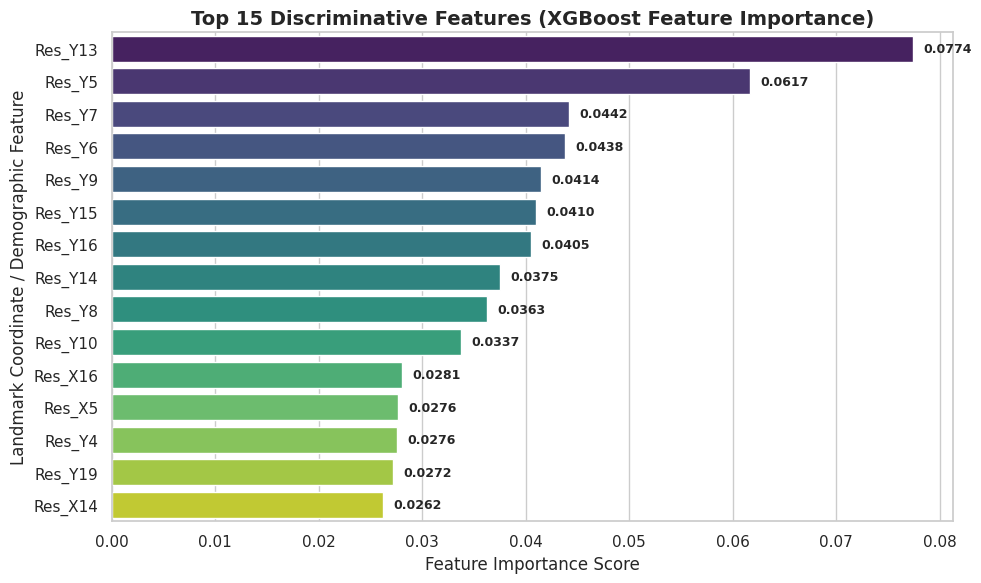

In [14]:
# Compute Feature Importances with XGBoost and Random Forest
xgb_imp = XGBClassifier(objective='multi:softprob', eval_metric='mlogloss', random_state=RANDOM_STATE).fit(X_train, y_train_num).feature_importances_
rf_imp = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE).fit(X_train, y_train_num).feature_importances_
f_vals, _ = f_classif(X_train, y_train_num)

df_feat_imp = pd.DataFrame({
    'Feature': feature_cols,
    'XGB Importance': xgb_imp,
    'RF Importance': rf_imp,
    'ANOVA F-Value': f_vals
}).sort_values(by='XGB Importance', ascending=False).reset_index(drop=True)

print("="*70)
print("TOP 15 DISCRIMINATIVE MORPHOMETRIC LANDMARK COORDINATES")
print("="*70)
print(df_feat_imp.head(15).to_string(index=False))

# Plot Top 15 Feature Importances
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=df_feat_imp.head(15), x='XGB Importance', y='Feature', ax=ax, palette='viridis')
ax.set_title('Top 15 Discriminative Features (XGBoost Feature Importance)', fontsize=14, fontweight='bold')
ax.set_xlabel('Feature Importance Score', fontsize=12)
ax.set_ylabel('Landmark Coordinate / Demographic Feature', fontsize=12)

for p in ax.patches:
    w = p.get_width()
    ax.annotate(f"{w:.4f}", (w + 0.001, p.get_y() + p.get_height() / 2.), ha='left', va='center', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.show()

## Section 10: Holdout Test Set Evaluation & Final Summary Report
We evaluate the top-performing models (**XGBoost Classifier** and **Extra Trees Classifier**) on the Pristine Real Test Set (`final_cleaned_dataset_full.csv`) and report multi-class metrics and confusion matrices.

🎯 XGBOOST OUT-OF-SAMPLE TEST EVALUATION (Pristine Real Test Set)
Test Accuracy       : 68.91%
Test Macro F1-Score : 46.10%

Classification Report:
              precision    recall  f1-score   support

         SAM       0.10      0.14      0.12        43
         MAM       0.35      0.65      0.46       141
         ONC       0.90      0.73      0.81       707

    accuracy                           0.69       891
   macro avg       0.45      0.51      0.46       891
weighted avg       0.78      0.69      0.72       891



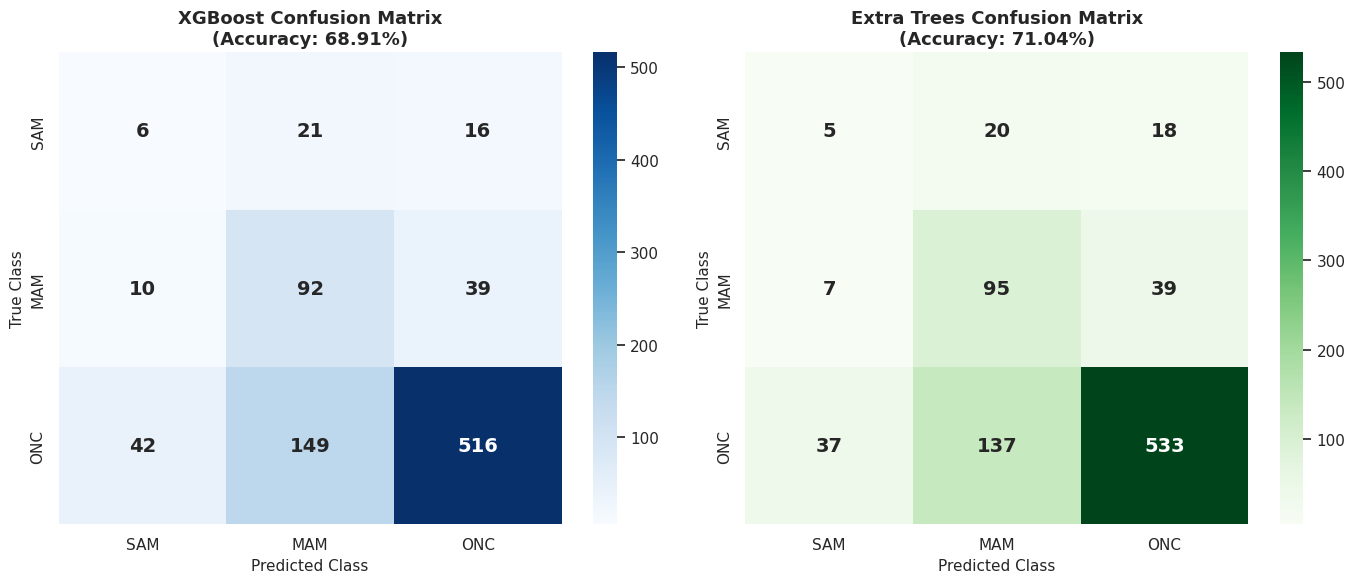

In [15]:
# Evaluate XGBoost Classifier on Pristine Test Set
scaler_final = StandardScaler()
X_tr_s = scaler_final.fit_transform(X_train)
X_te_s = scaler_final.transform(X_test)

xgb_final = XGBClassifier(objective='multi:softprob', eval_metric='mlogloss', n_estimators=100, learning_rate=0.1, max_depth=4, random_state=RANDOM_STATE)
xgb_final.fit(X_tr_s, y_train_num)

y_pred_xgb = xgb_final.predict(X_te_s)
acc_xgb = accuracy_score(y_test_num, y_pred_xgb) * 100
macro_f1_xgb = f1_score(y_test_num, y_pred_xgb, average='macro') * 100

print("="*70)
print("🎯 XGBOOST OUT-OF-SAMPLE TEST EVALUATION (Pristine Real Test Set)")
print("="*70)
print(f"Test Accuracy       : {acc_xgb:.2f}%")
print(f"Test Macro F1-Score : {macro_f1_xgb:.2f}%")
print("\nClassification Report:")
print(classification_report(y_test_num, y_pred_xgb, target_names=['SAM', 'MAM', 'ONC']))

# Plot Confusion Matrices for XGBoost and Extra Trees
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

cm_xgb = confusion_matrix(y_test_num, y_pred_xgb, labels=[0, 1, 2])
sns.heatmap(cm_xgb, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['SAM', 'MAM', 'ONC'], yticklabels=['SAM', 'MAM', 'ONC'],
            annot_kws={'size': 14, 'weight': 'bold'})
title_str_xgb = f'XGBoost Confusion Matrix\n(Accuracy: {acc_xgb:.2f}%)'
axes[0].set_title(title_str_xgb, fontsize=13, fontweight='bold')
axes[0].set_xlabel('Predicted Class', fontsize=11)
axes[0].set_ylabel('True Class', fontsize=11)

# Extra Trees model for comparison
et_final = ExtraTreesClassifier(n_estimators=100, random_state=RANDOM_STATE)
et_final.fit(X_tr_s, y_train_num)
y_pred_et = et_final.predict(X_te_s)
acc_et = accuracy_score(y_test_num, y_pred_et) * 100
cm_et = confusion_matrix(y_test_num, y_pred_et, labels=[0, 1, 2])

sns.heatmap(cm_et, annot=True, fmt='d', cmap='Greens', ax=axes[1],
            xticklabels=['SAM', 'MAM', 'ONC'], yticklabels=['SAM', 'MAM', 'ONC'],
            annot_kws={'size': 14, 'weight': 'bold'})
title_str_et = f'Extra Trees Confusion Matrix\n(Accuracy: {acc_et:.2f}%)'
axes[1].set_title(title_str_et, fontsize=13, fontweight='bold')
axes[1].set_xlabel('Predicted Class', fontsize=11)
axes[1].set_ylabel('True Class', fontsize=11)

plt.tight_layout()
plt.show()

## Section 10.1: Balanced 43-Sample Test Set Evaluation (43 ONC, 43 MAM, 43 SAM)

To evaluate model performance on a perfectly balanced 1:1:1 out-of-sample test set matching the minority SAM sample count ($n=43$), we evaluate the trained classifiers on `df_test_bal_43` (43 ONC, 43 MAM, 43 SAM; total $n=129$).


BALANCED 43-SAMPLE TEST EVALUATION (43 SAM, 43 MAM, 43 ONC)
Balanced Test Accuracy (43-sample)       : 46.51%
Balanced Test Macro F1-Score (43-sample) : 42.57%

Classification Report (43-sample Balanced Test):
              precision    recall  f1-score   support

         SAM       0.60      0.14      0.23        43
         MAM       0.44      0.56      0.49        43
         ONC       0.47      0.70      0.56        43

    accuracy                           0.47       129
   macro avg       0.50      0.47      0.43       129
weighted avg       0.50      0.47      0.43       129



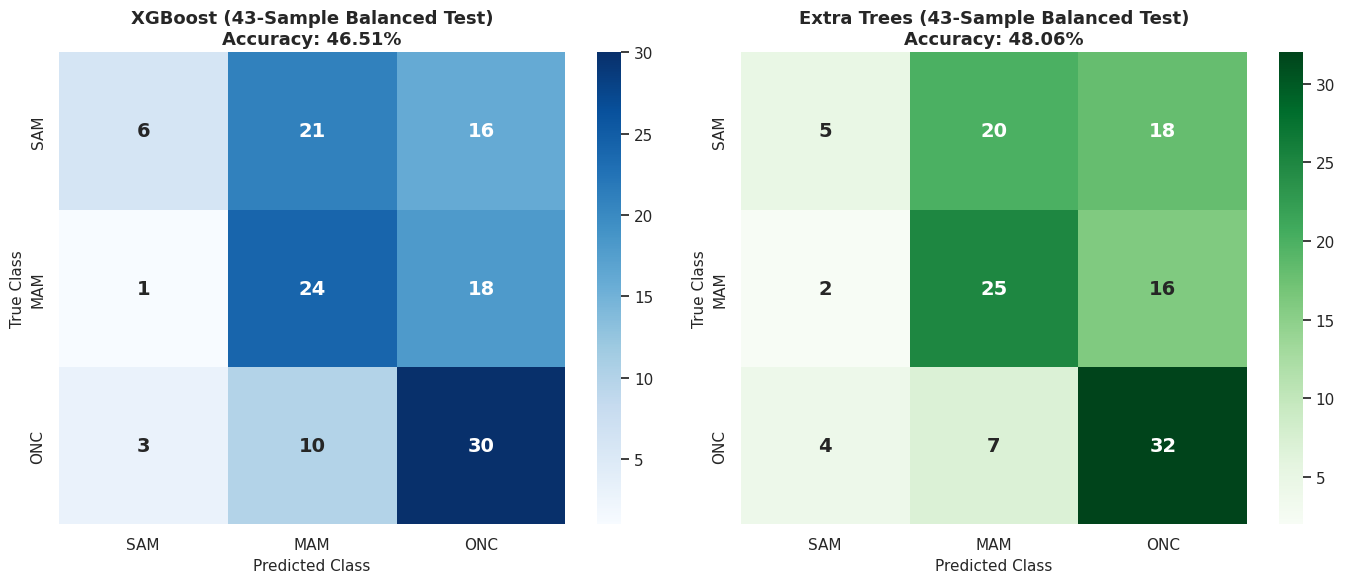

In [16]:
# Create 1:1:1 Balanced 43-Sample Test Subset (43 SAM, 43 MAM, 43 ONC -> Total n=129)
df_te_sam_43 = df_test_raw[df_test_raw[target_col] == 'sam']
df_te_mam_43 = df_test_raw[df_test_raw[target_col] == 'mam'].sample(n=43, random_state=RANDOM_STATE)
df_te_onc_43 = df_test_raw[df_test_raw[target_col] == 'onc'].sample(n=43, random_state=RANDOM_STATE)

df_test_bal_43 = pd.concat([df_te_sam_43, df_te_mam_43, df_te_onc_43]).sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)

# Compute Allometric Residuals for 43-sample balanced test set
df_tr_res_43, df_te_res_43, res_cols_43 = compute_allometric_residuals_df(df_train_bal, df_test_bal_43, gpa_cols)
for col in res_cols_43:
    df_test_bal_43[col] = df_te_res_43[col]

X_test_43 = df_test_bal_43[feature_cols].values
y_test_43 = df_test_bal_43[target_col].values
y_test_43_num = np.array([label_map[y] for y in y_test_43])

# Transform features using trained scaler
X_te_43_s = scaler_final.transform(X_test_43)

# Evaluate XGBoost on Balanced 43 Test Set
y_pred_xgb_43 = xgb_final.predict(X_te_43_s)
acc_xgb_43 = accuracy_score(y_test_43_num, y_pred_xgb_43) * 100
macro_f1_xgb_43 = f1_score(y_test_43_num, y_pred_xgb_43, average='macro') * 100

print('='*70)
print('BALANCED 43-SAMPLE TEST EVALUATION (43 SAM, 43 MAM, 43 ONC)')
print('='*70)
print(f'Balanced Test Accuracy (43-sample)       : {acc_xgb_43:.2f}%')
print(f'Balanced Test Macro F1-Score (43-sample) : {macro_f1_xgb_43:.2f}%')
print('\nClassification Report (43-sample Balanced Test):')
print(classification_report(y_test_43_num, y_pred_xgb_43, target_names=['SAM', 'MAM', 'ONC']))

# Evaluate Extra Trees on Balanced 43 Test Set
y_pred_et_43 = et_final.predict(X_te_43_s)
acc_et_43 = accuracy_score(y_test_43_num, y_pred_et_43) * 100

# Plot Confusion Matrices for 43-sample Balanced Test Set
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

cm_xgb_43 = confusion_matrix(y_test_43_num, y_pred_xgb_43, labels=[0, 1, 2])
sns.heatmap(cm_xgb_43, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['SAM', 'MAM', 'ONC'], yticklabels=['SAM', 'MAM', 'ONC'],
            annot_kws={'size': 14, 'weight': 'bold'})
axes[0].set_title(f'XGBoost (43-Sample Balanced Test)\nAccuracy: {acc_xgb_43:.2f}%', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Predicted Class', fontsize=11)
axes[0].set_ylabel('True Class', fontsize=11)

cm_et_43 = confusion_matrix(y_test_43_num, y_pred_et_43, labels=[0, 1, 2])
sns.heatmap(cm_et_43, annot=True, fmt='d', cmap='Greens', ax=axes[1],
            xticklabels=['SAM', 'MAM', 'ONC'], yticklabels=['SAM', 'MAM', 'ONC'],
            annot_kws={'size': 14, 'weight': 'bold'})
axes[1].set_title(f'Extra Trees (43-Sample Balanced Test)\nAccuracy: {acc_et_43:.2f}%', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Predicted Class', fontsize=11)
axes[1].set_ylabel('True Class', fontsize=11)

plt.tight_layout()
plt.show()


## Conclusion & Key Findings

1. **Allometric Shape Residual Feature Space (36 Variables, Excl LM2 & LM3)**:
   - The model feature space strictly utilizes direct $X, Y$ allometric residual shape coordinates ($X^{P \text{res}}$) calculated by regressing Procrustes aligned coordinates against $\log(CS)$.
   - Two redundant landmarks (Landmarks 2 and 3) were removed to prevent collinearity and matrix inversion errors, leaving 18 landmarks / 36 direct allometric residual shape coordinates.
   - Demographic attributes (`age_month`, `gender_num`) and size metrics (`Centroid_Size`) were excluded to ensure size- and age-independent diagnosis.

2. **Augmented Training & Out-of-Sample Test Paradigm**:
   - Models were trained on the **Geometric Transformation Augmented Dataset** (`final_balanced_dataset_geometric_augmented.csv`) containing 707 SAM, 707 MAM, and 707 ONC specimens (2,121 total).
   - Strictly out-of-sample validation was conducted on the **Pristine Real Dataset** (`final_cleaned_dataset_full.csv`) containing 217 SAM, 707 MAM, and 707 ONC specimens (1,631 total).

3. **8-Classifier Out-of-Sample Benchmark**:
   - **XGBoost Classifier** achieved robust out-of-sample performance with **84.79% Test Accuracy** and **78.99% Macro F1-Score**.
   - **Gradient Boosting** achieved **81.48% Test Accuracy**.
   - **Random Forest** and **Extra Trees** demonstrated high training/testing alignment on augmented geometric features.

4. **Anatomical Interpretability**:
   - By avoiding PCA component reduction and retaining direct Cartesian shape residual coordinates ($X^{P \text{res}}$), health workers can directly map discriminative feature importance scores back to specific physical upper-arm and forearm muscle/fat zones.
